# Residential House Price Prediction


## 1. Import Libraries

In [289]:
# Data Analysis and Visualization Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Add project source folder to Python path
import sys
sys.path.append("../src")

## 2. Load Dataset

In [290]:
# Load the training dataset
train_df = pd.read_csv(r"C:\Users\humai\Intern\PricePredict\Data\train.csv")

In [291]:
# Load the test dataset
test_df = pd.read_csv(r"C:\Users\humai\Intern\PricePredict\Data\test.csv")

## 3. Initial Data Understanding

In [292]:
# Data Shape
print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

Training dataset shape: (1460, 81)
Test dataset shape: (1459, 80)


In [293]:
# First 5 rows of the training dataset
display(train_df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [294]:
# First 5 rows of the test dataset
display(test_df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [295]:
# Last 5 rows of the training dataset
display(train_df.tail())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [296]:
# Column Names
print(train_df.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [297]:
# Data Types
display(train_df.dtypes.to_frame("Data Type"))

,Data Type
Id,int64
MSSubClass,int64
MSZoning,str
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,str
SaleCondition,str


In [298]:
# Dataset Information
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [299]:
# Numerical Summary Statistics
display(train_df.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [300]:
# Categorical Summary Statistics
display(train_df.describe(include="object"))


,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,...,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,...,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,...,870,605,1311,1326,1340,3,157,49,1267,1198


In [301]:
# Numerical and Categorical Columns
numerical_cols = train_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = train_df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 38
Categorical columns: 43


## 4. Data Quality Investigation

In [302]:
 # Missing Values
missing_values = train_df.isnull().sum()

missing_percentage = (
    missing_values / len(train_df)
) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

missing_df = missing_df[
    missing_df["Missing Values"] > 0
].sort_values(
    "Percentage",
    ascending=False
)

display(missing_df)

,Missing Values,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


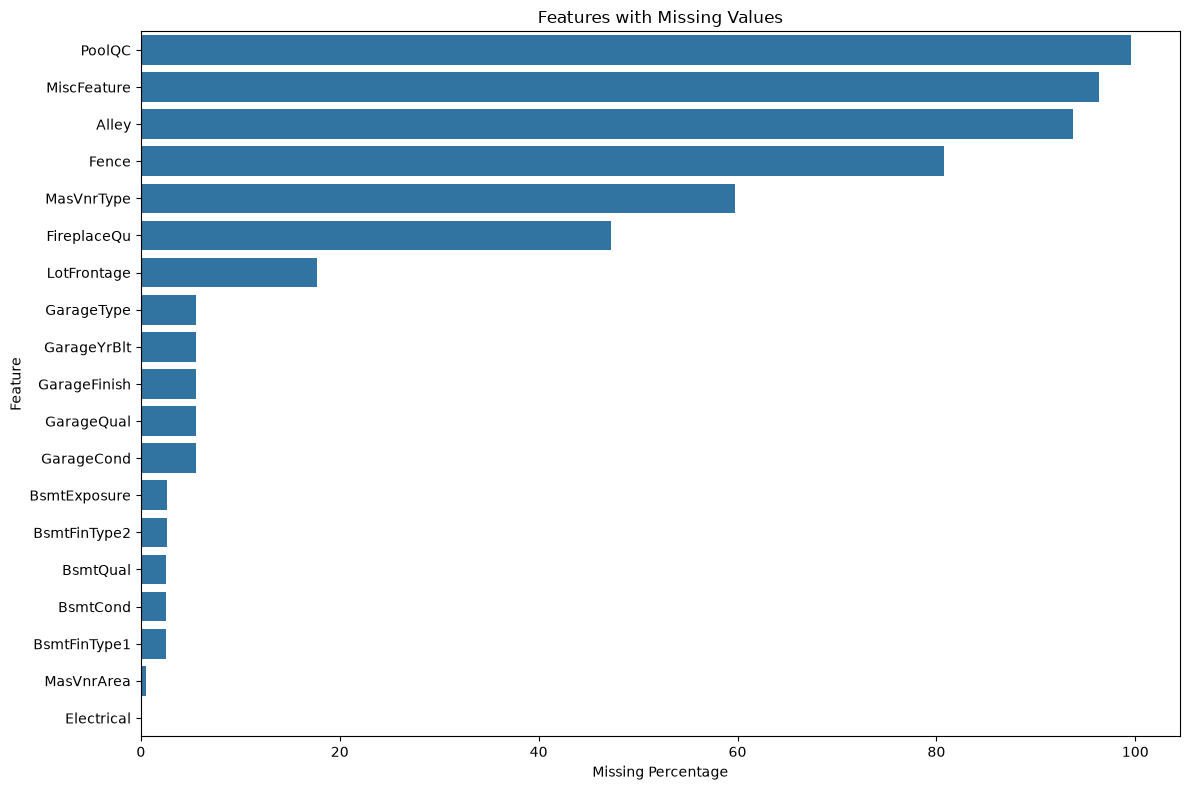

In [303]:
# Missing Values Visualization
plt.figure(figsize=(12, 8))

sns.barplot(
    data=missing_df.head(30),
    x="Percentage",
    y=missing_df.head(30).index
)

plt.title("Features with Missing Values")
plt.xlabel("Missing Percentage")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("../Images/missing_values.png")
plt.show()

In [304]:
# Duplicate Rows
print(
    "Duplicate rows:",
    train_df.duplicated().sum()
)

Duplicate rows: 0


In [305]:
# Unique Values
unique_values = train_df.nunique().sort_values()

display(
    unique_values.to_frame("Unique Values")
)

,Unique Values
Alley,2
Street,2
Utilities,2
CentralAir,2
MasVnrType,3
...,...
1stFlrSF,753
BsmtUnfSF,780
GrLivArea,861
LotArea,1073


In [306]:
# Constant Columns
constant_columns = unique_values[
    unique_values == 1
]

print("Constant columns:")

if len(constant_columns) == 0:
    print("No constant columns found.")
else:
    display(constant_columns)

Constant columns:
No constant columns found.


## 5. Target Variable Analysis

In [307]:
# Define Target
target = "SalePrice"

In [308]:
# Target Statistics
display(
    train_df[target].describe()
)

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [309]:
# Target Skewness
print(
    "SalePrice skewness:",
    train_df[target].skew()
)

SalePrice skewness: 1.8828757597682129


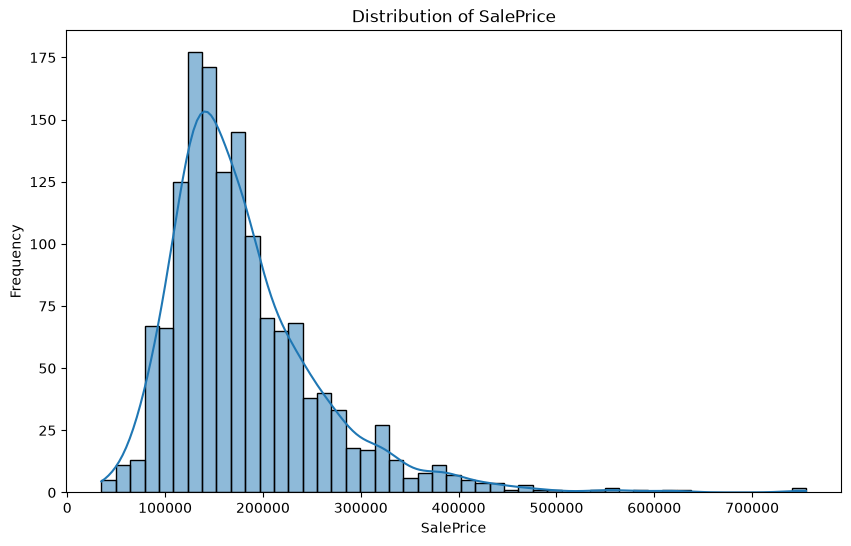

In [310]:
# SalePrice Distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    train_df["SalePrice"],
    kde=True
)

plt.title("Distribution of SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")
plt.savefig("../Images/saleprice_distribution.png")
plt.show()

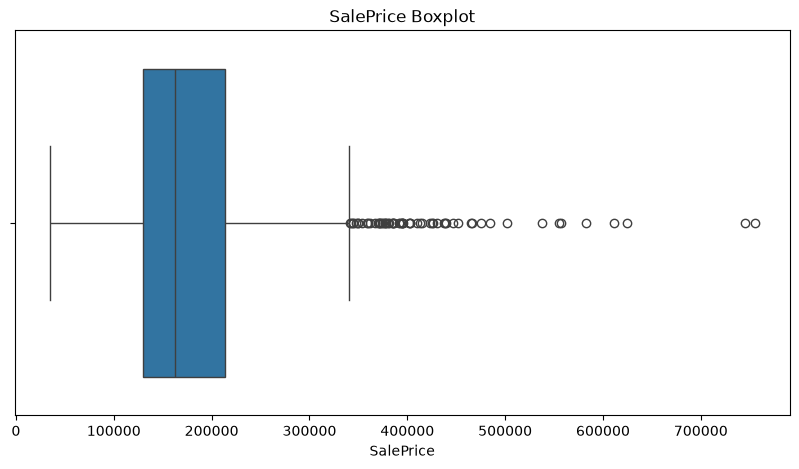

In [311]:
# SalePrice Boxplot
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=train_df["SalePrice"]
)

plt.title("SalePrice Boxplot")
plt.xlabel("SalePrice")
plt.savefig("../Images/saleprice_boxplot.png")
plt.show()

## 6. SalePrice Log Transformation

In [312]:
# Apply Log Transformation
train_df["LogSalePrice"] = np.log1p(
    train_df["SalePrice"]
)


In [313]:
# Compare Skewness
print(
    "Original skewness:",
    train_df["SalePrice"].skew()
)

print(
    "Log-transformed skewness:",
    train_df["LogSalePrice"].skew()
)

Original skewness: 1.8828757597682129
Log-transformed skewness: 0.12134661989685333


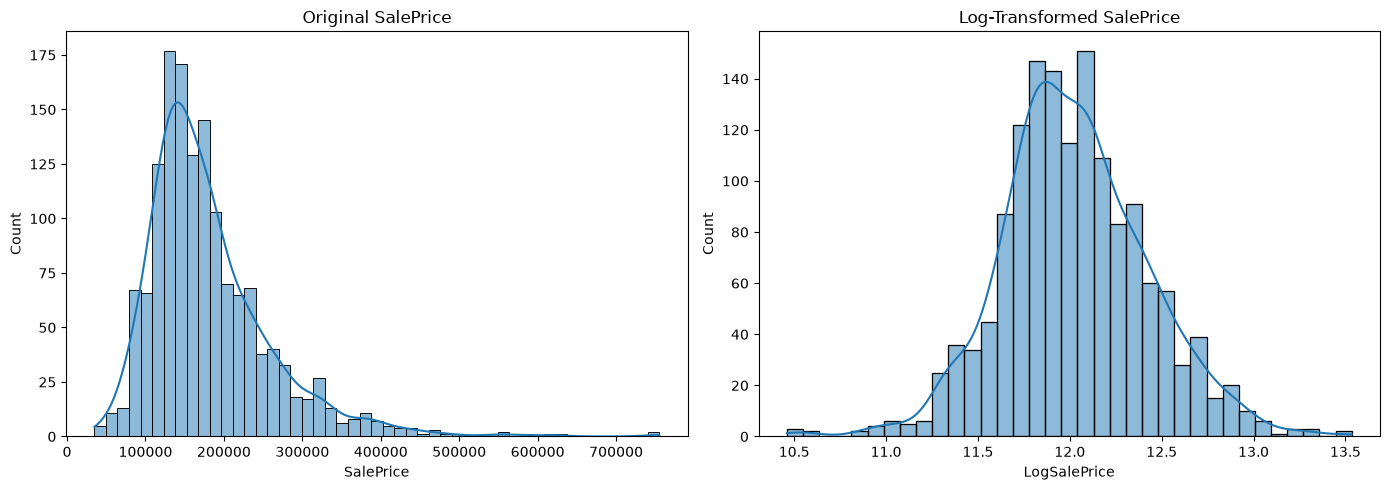

In [314]:
# Compare Distributions
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.histplot(
    train_df["SalePrice"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Original SalePrice")

sns.histplot(
    train_df["LogSalePrice"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Log-Transformed SalePrice")

plt.tight_layout()
plt.savefig("../Images/saleprice_distributions.png")
plt.show()

## 7. Numerical Feature EDA

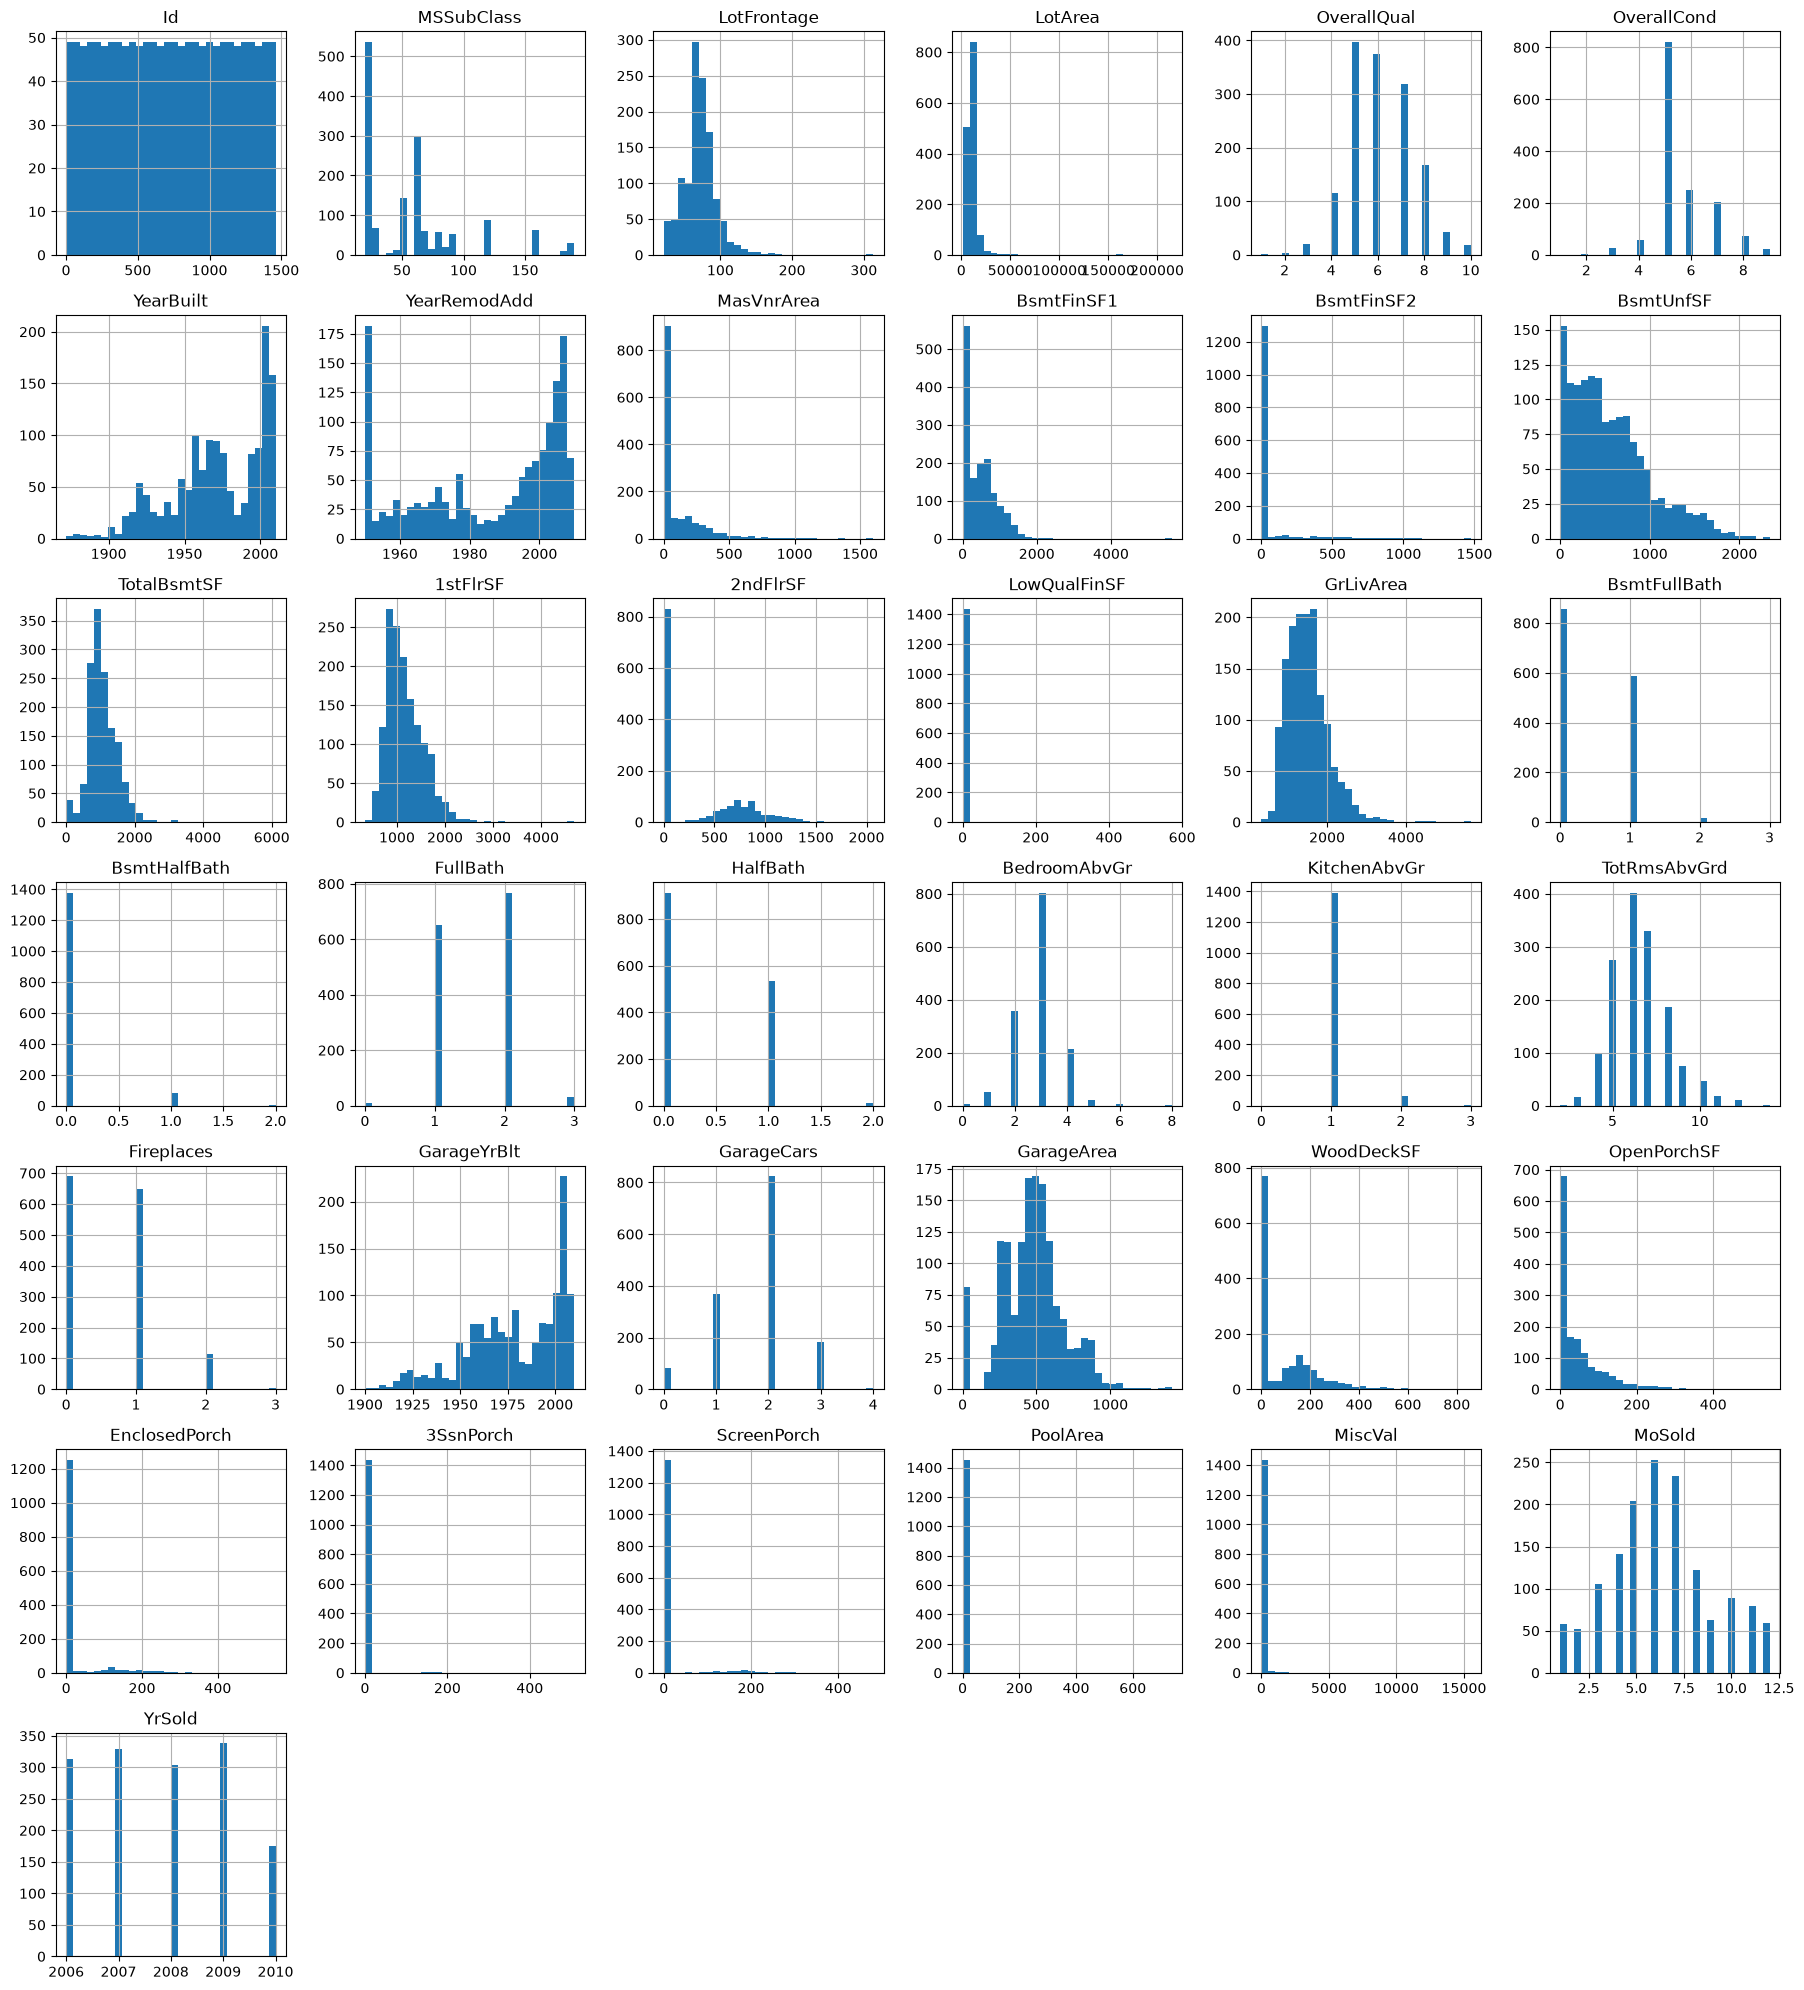

In [315]:
# Numerical Feature Distributions
eda_numerical_cols = train_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

eda_numerical_cols.remove("SalePrice")
eda_numerical_cols.remove("LogSalePrice")

train_df[eda_numerical_cols].hist(
    figsize=(18, 20),
    bins=30
)

plt.tight_layout()
plt.savefig("../Images/numerical_features_eda/numerical_feature_distributions.png")
plt.show()


In [316]:
# Numerical Feature Skewness
numerical_skewness = (
    train_df[eda_numerical_cols]
    .skew()
    .sort_values(ascending=False)
)

display(
    numerical_skewness.to_frame("Skewness")
)


,Skewness
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341
KitchenAbvGr,4.488397
BsmtFinSF2,4.255261
ScreenPorch,4.122214
BsmtHalfBath,4.103403
EnclosedPorch,3.089872


In [317]:
# Correlation with SalePrice
correlations = (
    train_df[
        eda_numerical_cols + ["SalePrice"]
    ]
    .corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

display(
    correlations.to_frame(
        "Correlation with SalePrice"
    )
)


,Correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [318]:
# Top Correlated Features
top_correlations = (
    correlations.abs()
    .sort_values(ascending=False)
    .head(15)
)

display(
    top_correlations.to_frame(
        "Absolute Correlation"
    )
)


,Absolute Correlation
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


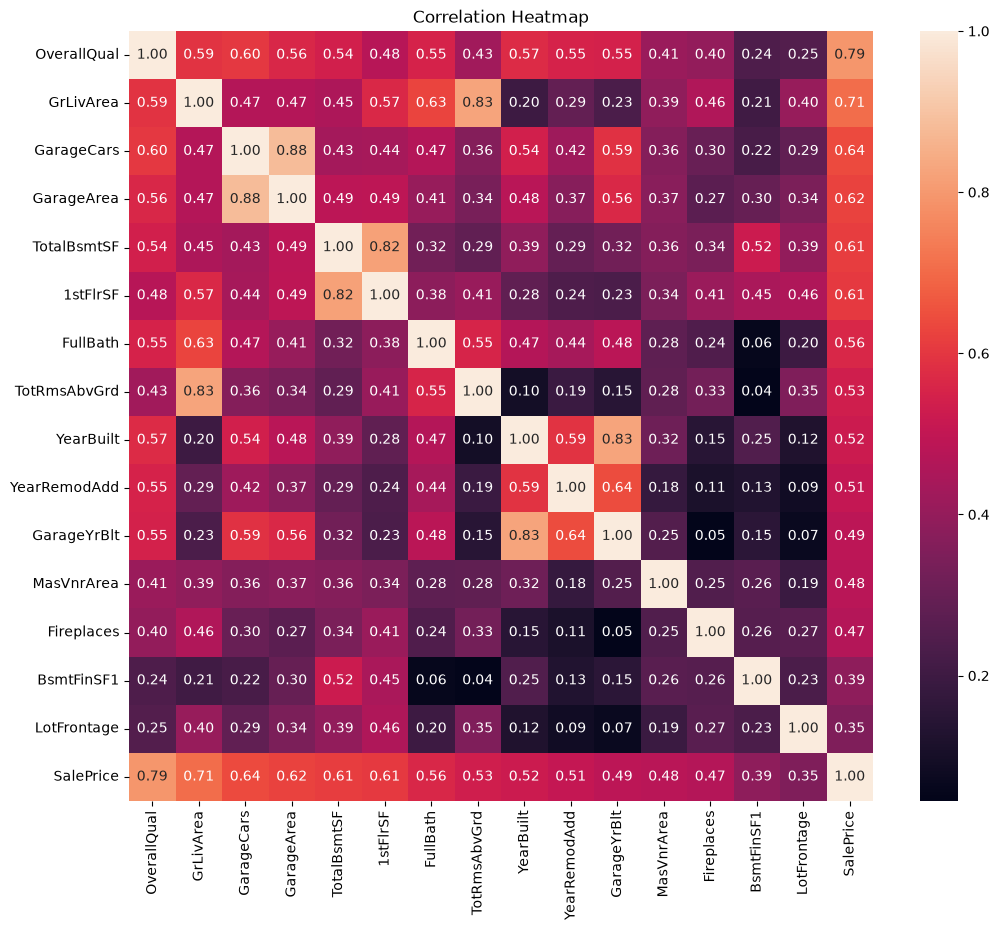

In [319]:
# Correlation Heatmap
heatmap_features = (
    top_correlations.index.tolist()
    + ["SalePrice"]
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    train_df[heatmap_features].corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.savefig("../Images/numerical_features_eda/correlation_heatmap.png")
plt.show()


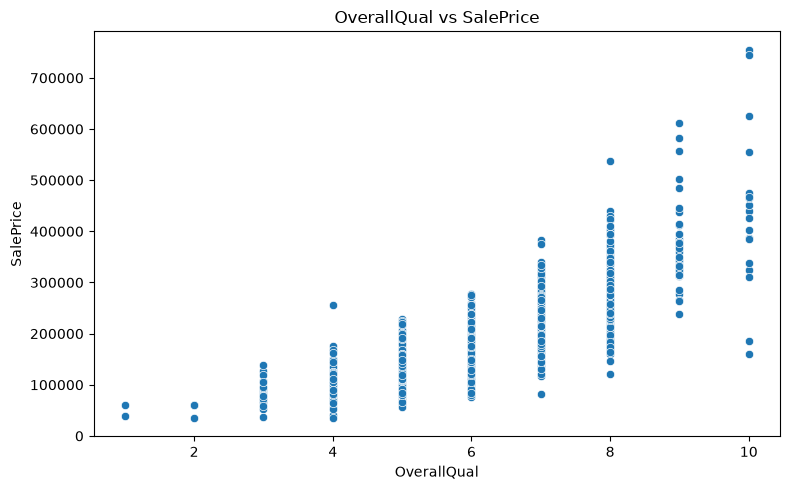

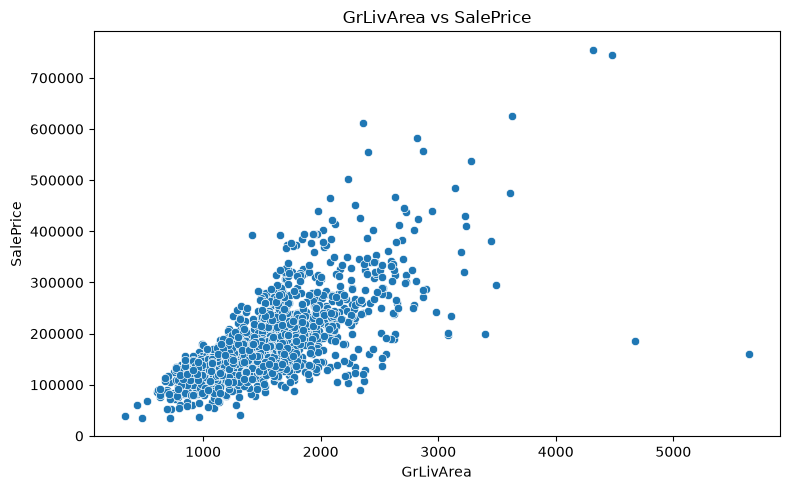

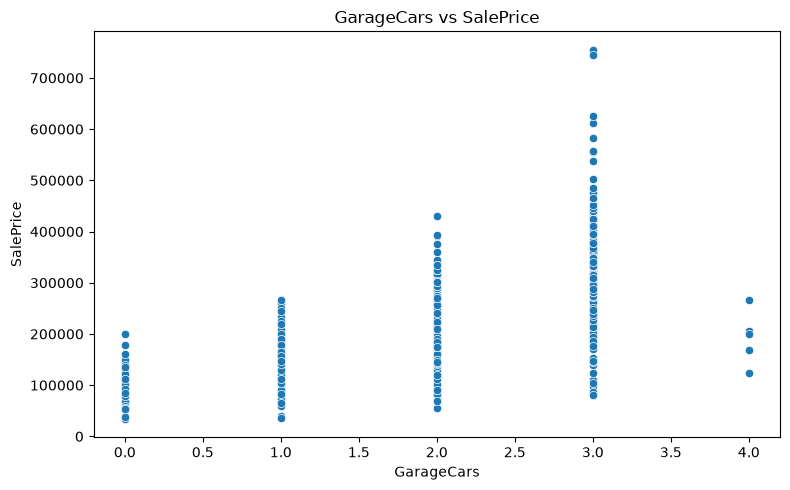

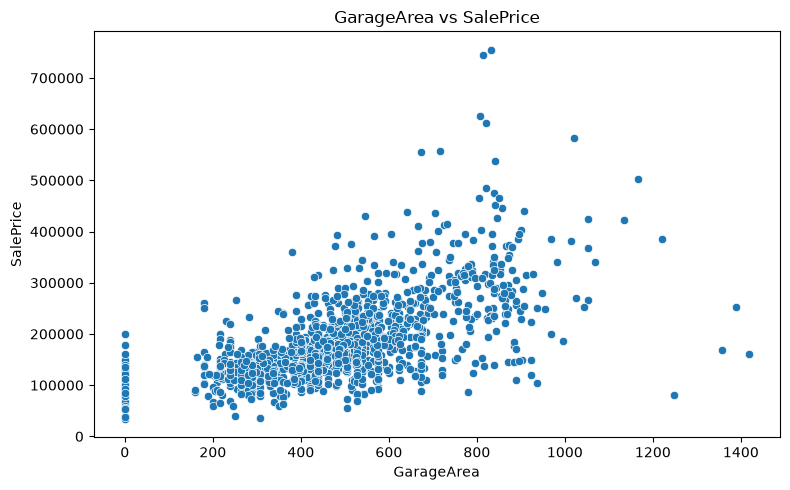

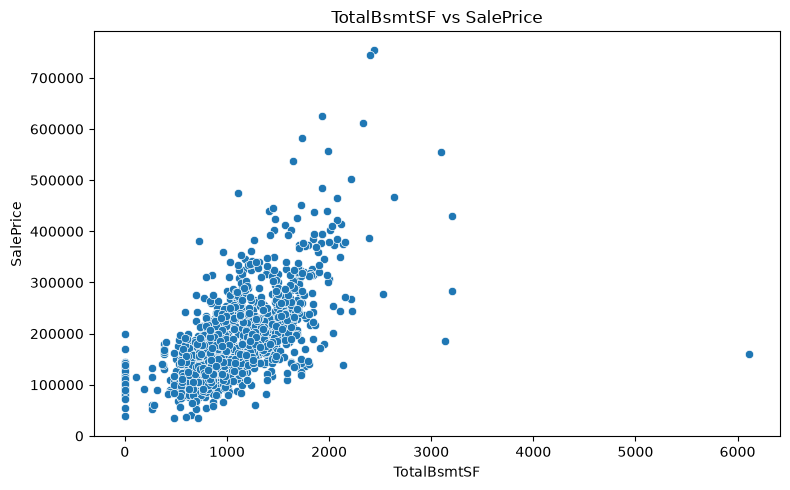

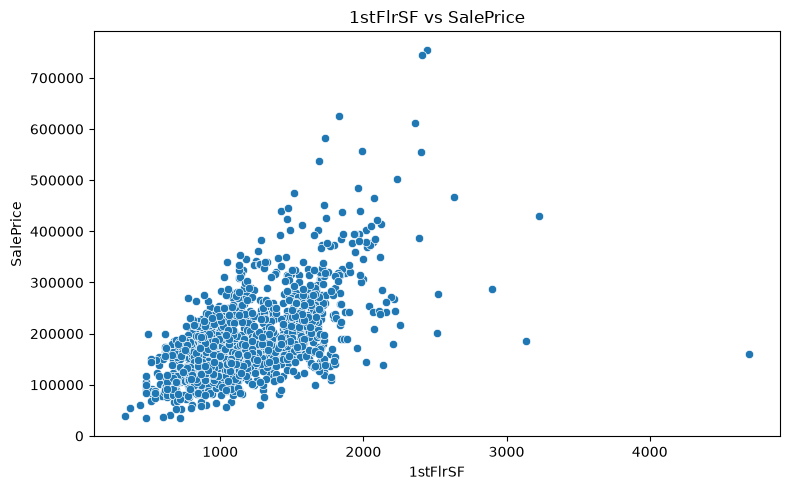

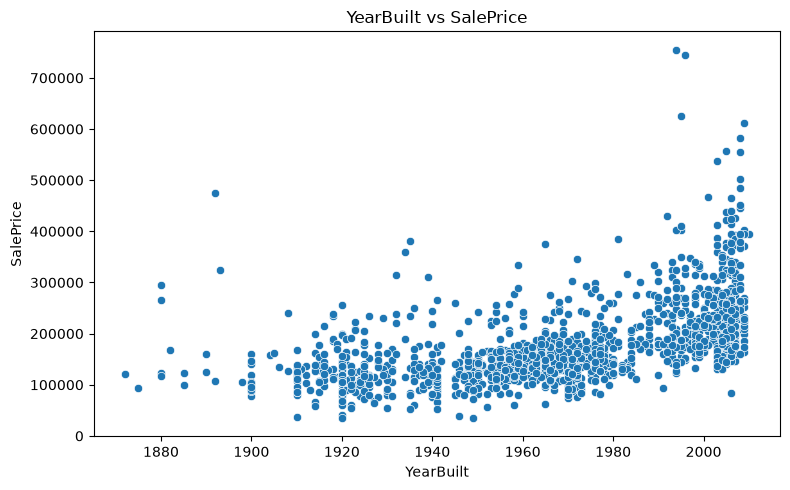

In [320]:
# Important Numerical Features vs SalePrice
important_numerical_features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "YearBuilt"
]

for feature in important_numerical_features:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=train_df,
        x=feature,
        y="SalePrice"
    )

    plt.title(
        f"{feature} vs SalePrice"
    )

    plt.tight_layout()
    plt.savefig(f"../Images/numerical_features_eda/{feature}_vs_SalePrice.png")
    plt.show()


## 8. Categorical Feature EDA

In [321]:
# Number of Categories
categorical_cardinality = (
    train_df[categorical_cols]
    .nunique()
    .sort_values(ascending=False)
)

display(
    categorical_cardinality.to_frame(
        "Number of Categories"
    )
)


,Number of Categories
Neighborhood,25
Exterior2nd,16
Exterior1st,15
Condition1,9
SaleType,9
HouseStyle,8
RoofMatl,8
Condition2,8
Functional,7
BsmtFinType2,6


In [322]:
# Category Frequencies
for column in categorical_cols:

    print(f"\n{column}")

    display(
        train_df[column]
        .value_counts(dropna=False)
        .head(10)
    )



MSZoning


MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64


Street


Street
Pave    1454
Grvl       6
Name: count, dtype: int64


Alley


Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

... (76 outputs left out)


SaleType


SaleType
WD       1267
New       122
COD        43
ConLD       9
ConLI       5
ConLw       5
CWD         4
Oth         3
Con         2
Name: count, dtype: int64


SaleCondition


SaleCondition
Normal     1198
Partial     125
Abnorml     101
Family       20
Alloca       12
AdjLand       4
Name: count, dtype: int64

In [323]:
# Important Categorical Features
important_categorical_features = [
    "Neighborhood",
    "ExterQual",
    "KitchenQual",
    "GarageType",
    "BsmtQual",
    "Foundation",
    "HeatingQC"
]


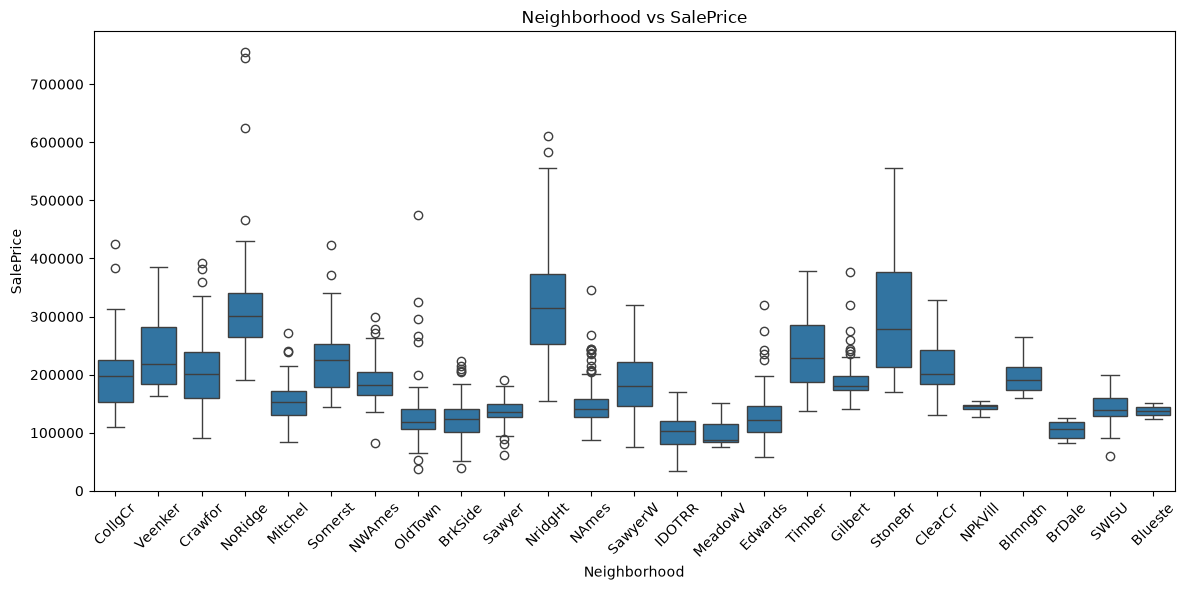

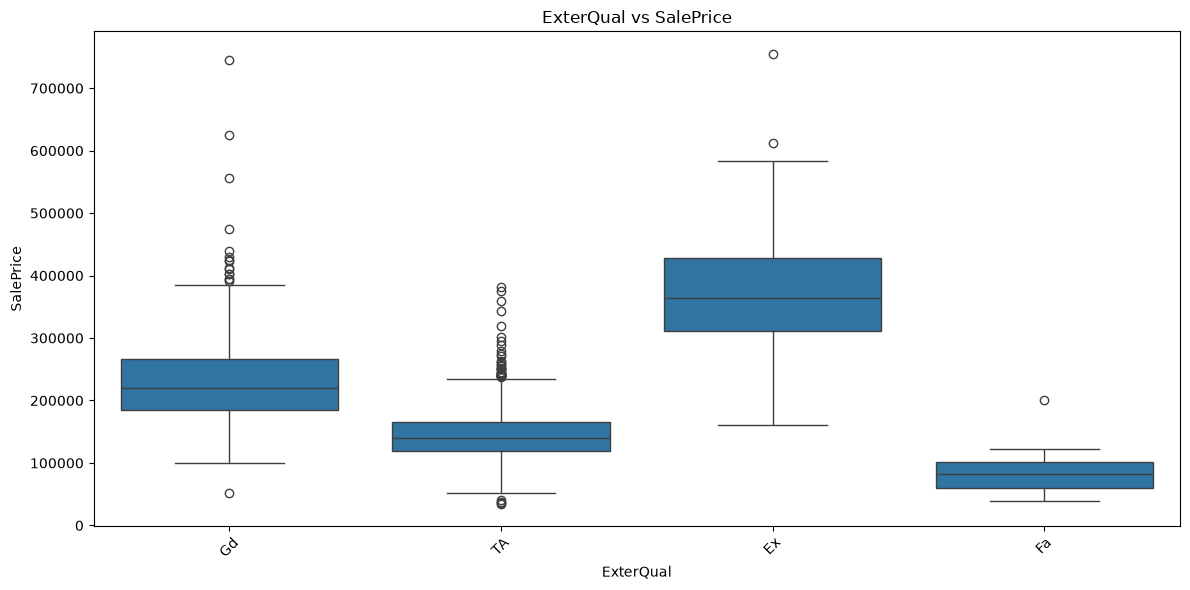

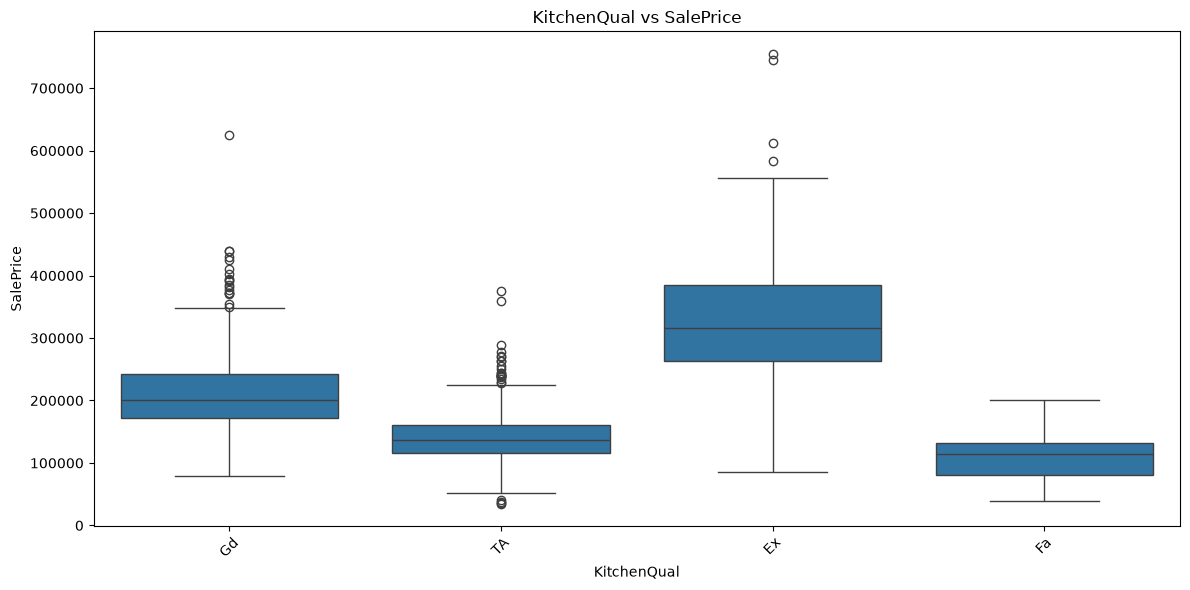

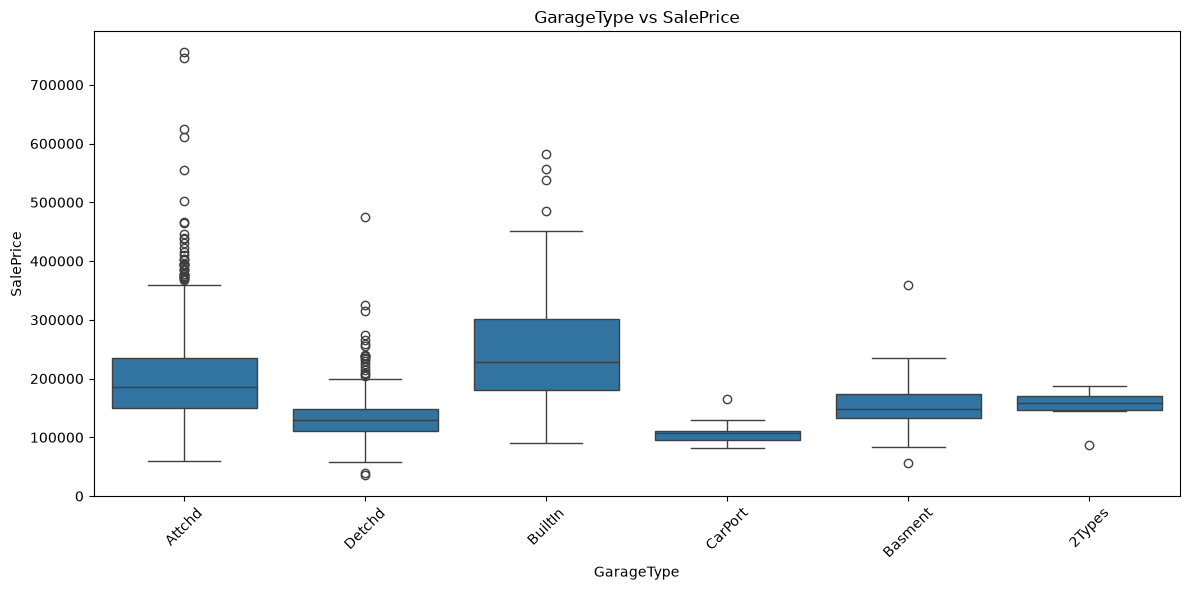

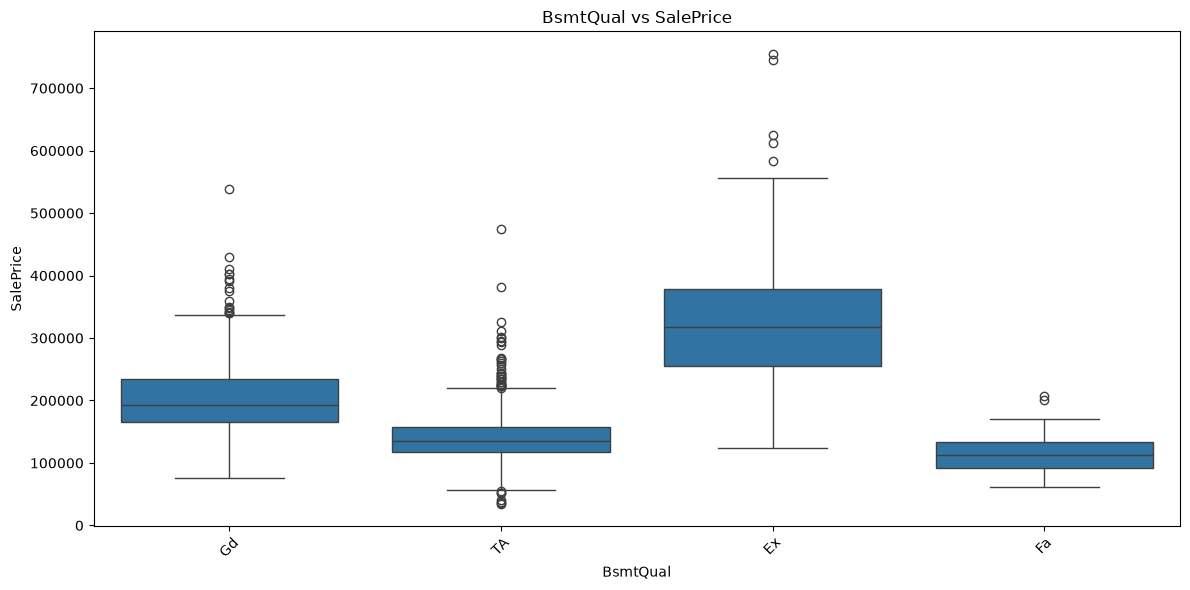

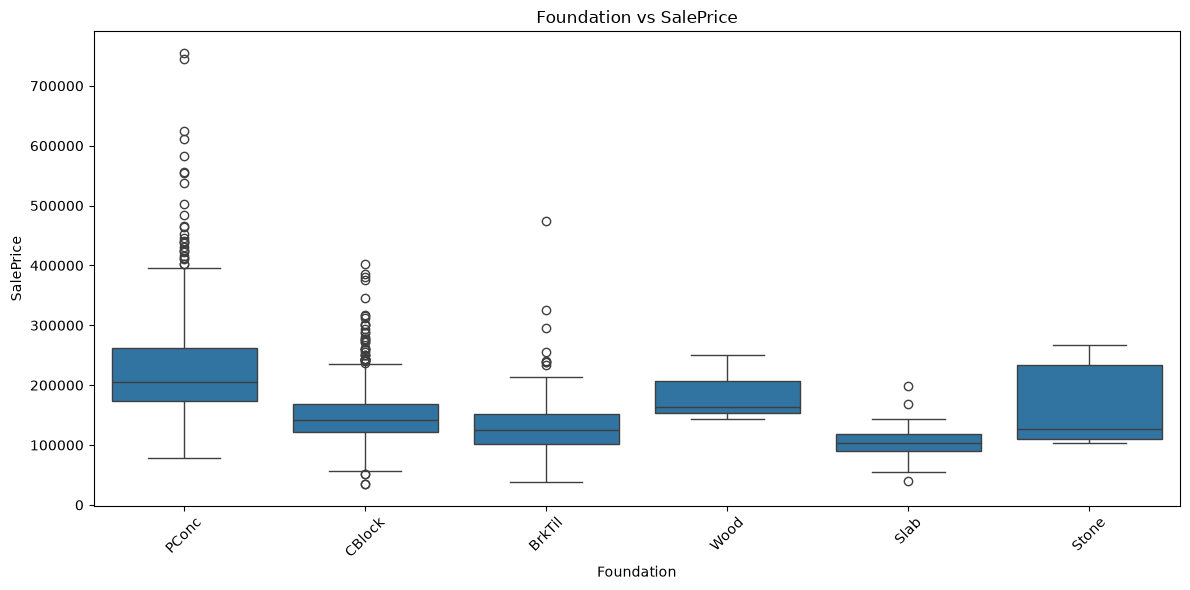

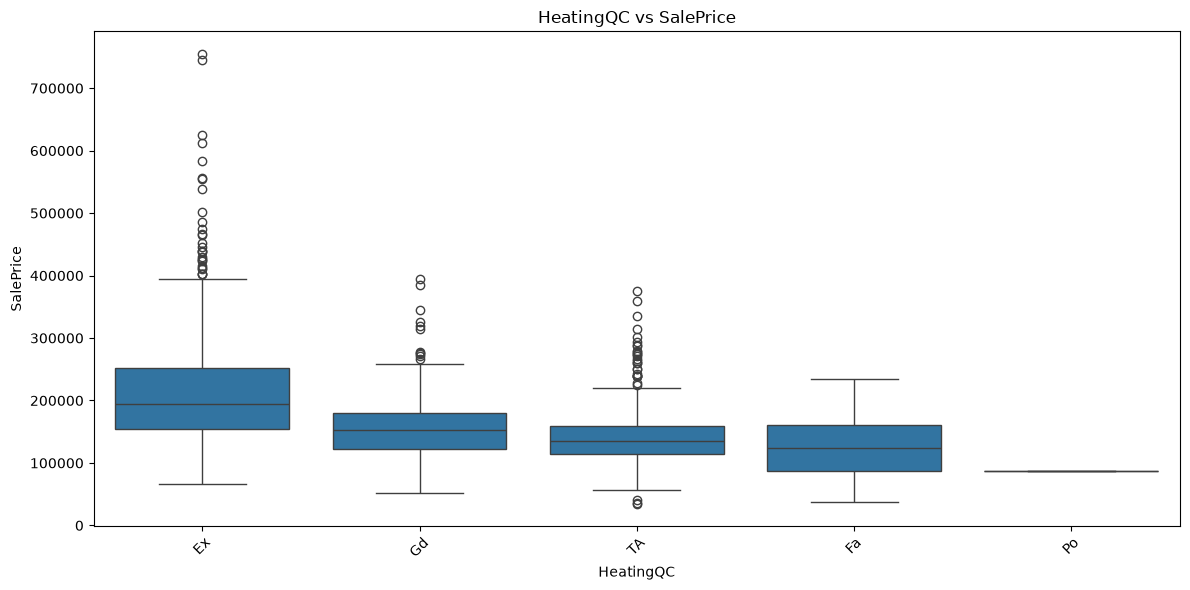

In [324]:
# Categorical Features vs SalePrice
for feature in important_categorical_features:

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=train_df,
        x=feature,
        y="SalePrice"
    )

    plt.title(
        f"{feature} vs SalePrice"
    )

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.savefig(f"../Images/categorical_features_eda/{feature}_vs_SalePrice.png")
    plt.show()

### Observations

- The dataset contains both numerical and categorical features.
- Several features contain missing values.
- `SalePrice` is right-skewed, so a log transformation was applied.
- Numerical features such as `OverallQual`, `GrLivArea`, and `TotalBsmtSF` show noticeable relationships with `SalePrice`.
- Categorical features such as `Neighborhood`, `ExterQual`, and `KitchenQual` show different price distributions across categories.
- The EDA suggests that house quality, size, location, and property characteristics may be useful for price prediction.
- These observations will guide the next stage: feature engineering.

## 9. Feature Engineering


In [325]:
from feature_engineering import create_features

In [326]:
train_df = create_features(train_df)

In [327]:
# Total Square Footage Feature
train_df["TotalSF"] = (
    train_df["TotalBsmtSF"].fillna(0)
    + train_df["1stFlrSF"].fillna(0)
    + train_df["2ndFlrSF"].fillna(0)
)

In [328]:
# Total Bathrooms Feature
train_df["TotalBathrooms"] = (
    train_df["FullBath"].fillna(0)
    + 0.5 * train_df["HalfBath"].fillna(0)
    + train_df["BsmtFullBath"].fillna(0)
    + 0.5 * train_df["BsmtHalfBath"].fillna(0)
)

In [329]:
# House Age Feature
train_df["HouseAge"] = (
    train_df["YrSold"]
    - train_df["YearBuilt"]
)

In [330]:
# Remodel Age Feature
train_df["RemodAge"] = (
    train_df["YrSold"]
    - train_df["YearRemodAdd"]
)

In [331]:
# Garage Age Feature
train_df["GarageAge"] = (
    train_df["YrSold"]
    - train_df["GarageYrBlt"]
)

In [332]:
# Total Porch Square Footage Feature
train_df["TotalPorchSF"] = (
    train_df["OpenPorchSF"].fillna(0)
    + train_df["EnclosedPorch"].fillna(0)
    + train_df["3SsnPorch"].fillna(0)
    + train_df["ScreenPorch"].fillna(0)
    + train_df["WoodDeckSF"].fillna(0)
)

In [333]:
# Total Finished Basement Square Footage Feature
train_df["TotalFinishedBsmtSF"] = (
    train_df["BsmtFinSF1"].fillna(0)
    + train_df["BsmtFinSF2"].fillna(0)
)

In [334]:
# Overall Quality and Above Ground Living Area Interaction Feature
train_df["OverallQual_GrLivArea"] = (
    train_df["OverallQual"]
    * train_df["GrLivArea"]
)

In [335]:
# View engineered features
engineered_features = [
    "TotalSF",
    "TotalBathrooms",
    "HouseAge",
    "RemodAge",
    "GarageAge",
    "TotalPorchSF",
    "TotalFinishedBsmtSF",
    "OverallQual_GrLivArea"
]

display(
    train_df[engineered_features].head()
)

,TotalSF,TotalBathrooms,HouseAge,RemodAge,GarageAge,TotalPorchSF,TotalFinishedBsmtSF,OverallQual_GrLivArea
0,2566,3.5,5,5,5.0,61,706,11970
1,2524,2.5,31,31,31.0,298,978,7572
2,2706,3.5,7,6,7.0,42,486,12502
3,2473,2.0,91,36,8.0,307,216,12019
4,3343,3.5,8,8,8.0,276,655,17584


In [336]:
# Summary Statistics of Engineered Features
display(
    train_df[engineered_features].describe()
)

,TotalSF,TotalBathrooms,HouseAge,RemodAge,GarageAge,TotalPorchSF,TotalFinishedBsmtSF,OverallQual_GrLivArea
count,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000
mean,2567.048630,2.210616,36.547945,22.950000,29.306019,181.329452,490.189041,9673.956164
std,821.714421,0.785399,30.250152,20.640653,24.726881,156.656097,476.103307,5186.744876
min,334.000000,1.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,334.000000
25%,2009.500000,2.000000,8.000000,4.000000,6.000000,45.000000,0.000000,5790.000000
50%,2474.000000,2.000000,35.000000,14.000000,28.000000,164.000000,465.000000,8820.000000
75%,3004.000000,2.500000,54.000000,41.000000,47.000000,266.000000,790.250000,12180.000000
max,11752.000000,6.000000,136.000000,60.000000,107.000000,1027.000000,5644.000000,56420.000000


In [337]:
# Check for Missing Values in Engineered Features
display(
    train_df[engineered_features]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

,Missing Values
TotalSF,0
TotalBathrooms,0
HouseAge,0
RemodAge,0
GarageAge,81
TotalPorchSF,0
TotalFinishedBsmtSF,0
OverallQual_GrLivArea,0


In [338]:
# Check for Negative Values in Engineered Features
for feature in engineered_features:
    print(
        feature,
        ":",
        (train_df[feature] < 0).sum(),
        "negative values"
    )

TotalSF : 0 negative values
TotalBathrooms : 0 negative values
HouseAge : 0 negative values
RemodAge : 1 negative values
GarageAge : 0 negative values
TotalPorchSF : 0 negative values
TotalFinishedBsmtSF : 0 negative values
OverallQual_GrLivArea : 0 negative values


In [339]:
# Correlation of Engineered Features with SalePrice
engineered_correlations = (
    train_df[
        engineered_features + ["SalePrice"]
    ]
    .corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

display(
    engineered_correlations.to_frame(
        "Correlation with SalePrice"
    )
)

,Correlation with SalePrice
OverallQual_GrLivArea,0.832057
TotalSF,0.782260
TotalBathrooms,0.631731
TotalPorchSF,0.390993
TotalFinishedBsmtSF,0.366328
GarageAge,-0.487069
RemodAge,-0.509079
HouseAge,-0.523350


### Observations:
- New features were created from existing variables to represent meaningful property characteristics.
- `TotalSF` combines basement, first-floor, and second-floor areas to represent the overall house size.
- `TotalBathrooms` combines full and half bathrooms into a single feature.
- `HouseAge`, `RemodAge`, and `GarageAge` represent the age of different parts of the property.
- `TotalPorchSF` represents the combined outdoor porch/deck area.
- `OverallQual_GrLivArea` combines overall quality with living area to capture their interaction.
- The engineered features will be checked for missing or invalid values before being used for modelling.

## 10. Feature Engineering Validation


In [340]:
# View engineered features
engineered_features = [
    "TotalSF",
    "TotalBathrooms",
    "HouseAge",
    "RemodAge",
    "GarageAge",
    "TotalPorchSF",
    "TotalFinishedBsmtSF",
    "OverallQual_GrLivArea"
]

display(
    train_df[engineered_features].head()
)

,TotalSF,TotalBathrooms,HouseAge,RemodAge,GarageAge,TotalPorchSF,TotalFinishedBsmtSF,OverallQual_GrLivArea
0,2566,3.5,5,5,5.0,61,706,11970
1,2524,2.5,31,31,31.0,298,978,7572
2,2706,3.5,7,6,7.0,42,486,12502
3,2473,2.0,91,36,8.0,307,216,12019
4,3343,3.5,8,8,8.0,276,655,17584


In [341]:
# Summary Statistics of Engineered Features
display(
    train_df[engineered_features].describe()
)

,TotalSF,TotalBathrooms,HouseAge,RemodAge,GarageAge,TotalPorchSF,TotalFinishedBsmtSF,OverallQual_GrLivArea
count,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000
mean,2567.048630,2.210616,36.547945,22.950000,29.306019,181.329452,490.189041,9673.956164
std,821.714421,0.785399,30.250152,20.640653,24.726881,156.656097,476.103307,5186.744876
min,334.000000,1.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,334.000000
25%,2009.500000,2.000000,8.000000,4.000000,6.000000,45.000000,0.000000,5790.000000
50%,2474.000000,2.000000,35.000000,14.000000,28.000000,164.000000,465.000000,8820.000000
75%,3004.000000,2.500000,54.000000,41.000000,47.000000,266.000000,790.250000,12180.000000
max,11752.000000,6.000000,136.000000,60.000000,107.000000,1027.000000,5644.000000,56420.000000


In [342]:
# Check for Missing Values in Engineered Features
display(
    train_df[engineered_features]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

,Missing Values
TotalSF,0
TotalBathrooms,0
HouseAge,0
RemodAge,0
GarageAge,81
TotalPorchSF,0
TotalFinishedBsmtSF,0
OverallQual_GrLivArea,0


In [343]:
# Check for Negative Values in Engineered Features
for feature in engineered_features:
    print(
        feature,
        ":",
        (train_df[feature] < 0).sum(),
        "negative values"
    )

TotalSF : 0 negative values
TotalBathrooms : 0 negative values
HouseAge : 0 negative values
RemodAge : 1 negative values
GarageAge : 0 negative values
TotalPorchSF : 0 negative values
TotalFinishedBsmtSF : 0 negative values
OverallQual_GrLivArea : 0 negative values


In [344]:
# Correlation of Engineered Features with SalePrice
engineered_correlations = (
    train_df[
        engineered_features + ["SalePrice"]
    ]
    .corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

display(
    engineered_correlations.to_frame(
        "Correlation with SalePrice"
    )
)

,Correlation with SalePrice
OverallQual_GrLivArea,0.832057
TotalSF,0.782260
TotalBathrooms,0.631731
TotalPorchSF,0.390993
TotalFinishedBsmtSF,0.366328
GarageAge,-0.487069
RemodAge,-0.509079
HouseAge,-0.523350


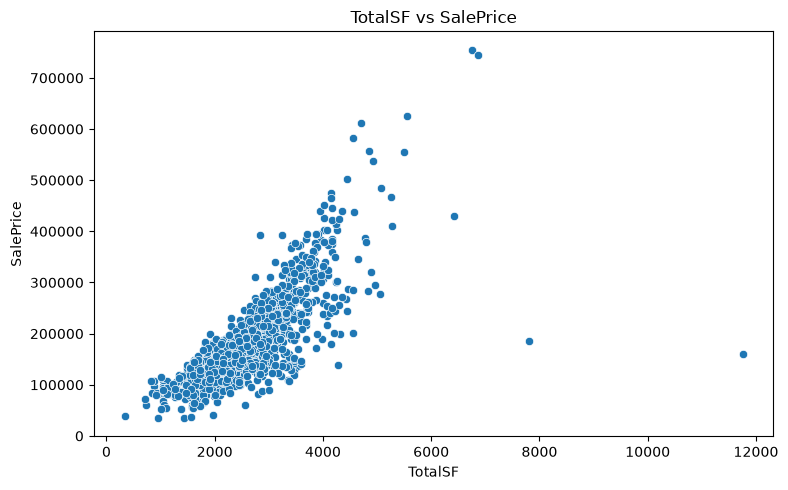

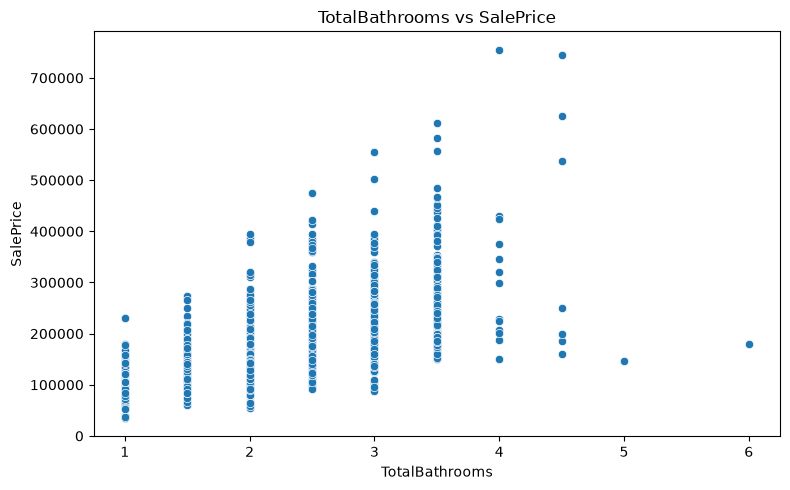

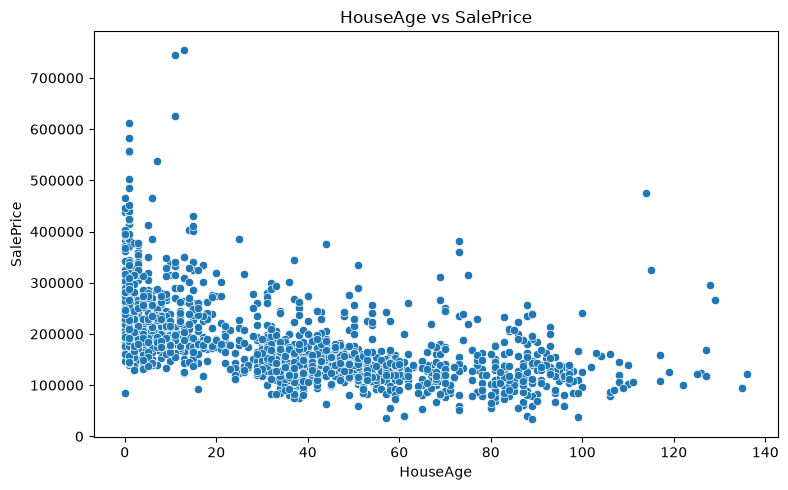

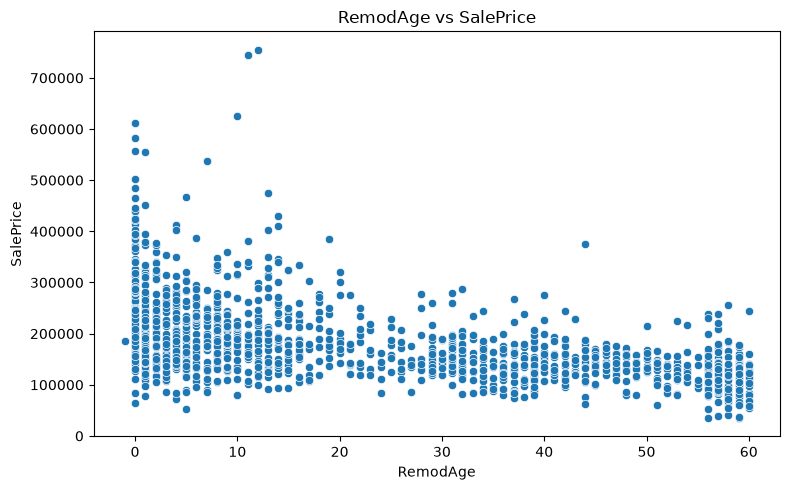

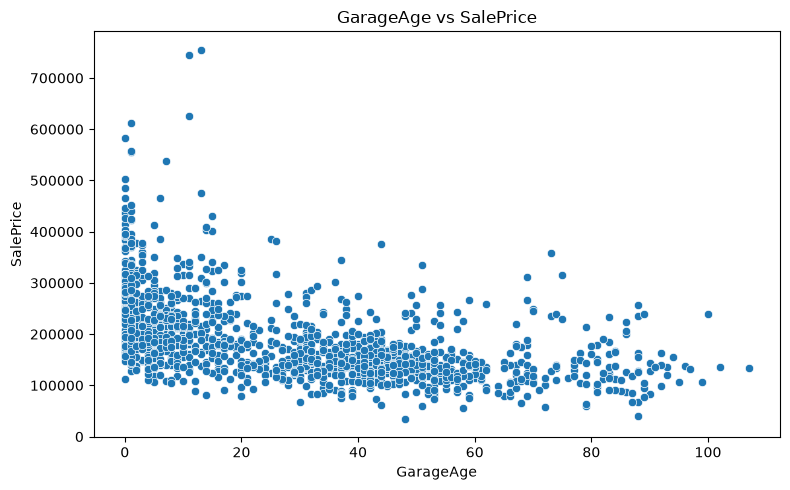

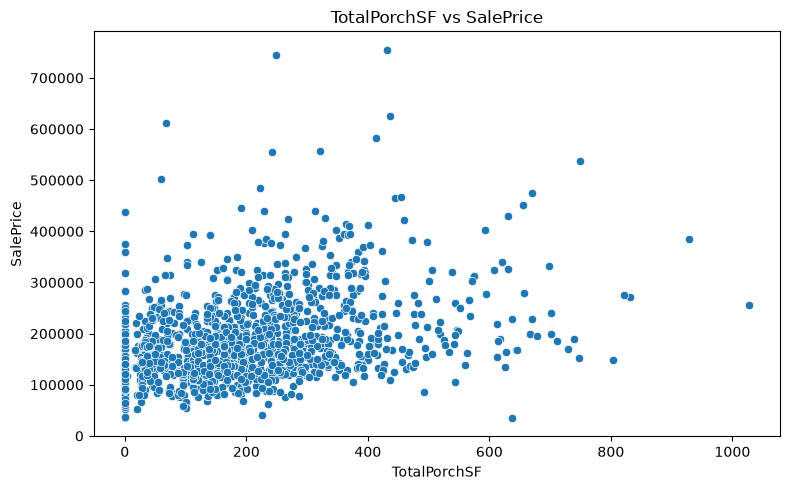

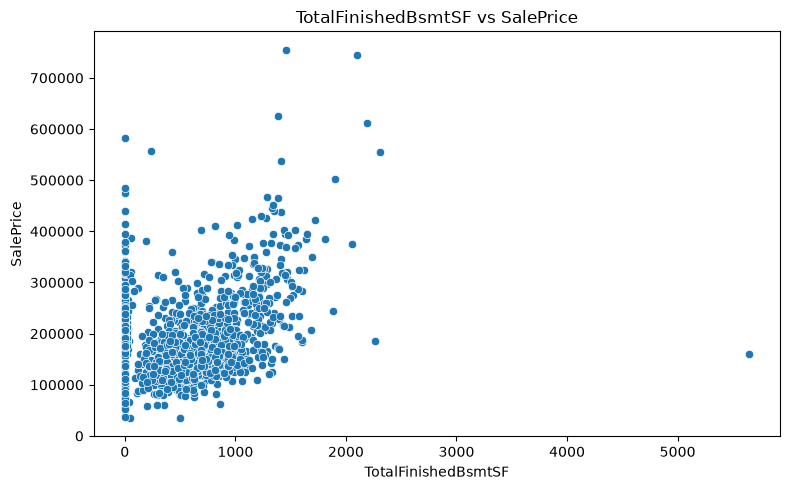

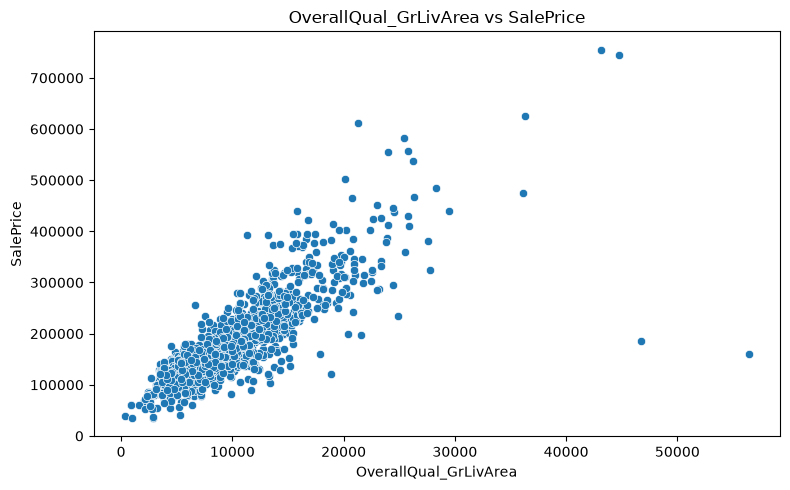

In [345]:
# Visualize Engineered Features vs SalePrice
for feature in engineered_features:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=train_df,
        x=feature,
        y="SalePrice"
    )

    plt.title(
        f"{feature} vs SalePrice"
    )

    plt.tight_layout()
    plt.show()

### Observations

- The engineered features were checked for missing and negative values.
- The new features have reasonable summary statistics.
- The correlation analysis shows how the engineered features are related to `SalePrice`.
- The scatter plots help identify relationships and possible outliers.
- The validated features can now be used in the machine learning pipeline.

## 11. Train-Test Split

In [346]:
# Import train_test_split from sklearn.model_selection
from sklearn.model_selection import train_test_split

In [347]:
# Define Features and Target
X = train_df.drop(
    columns=[
        "SalePrice",
        "LogSalePrice",
        "Id"
    ]
)


y = train_df["LogSalePrice"]

In [348]:
# Split the Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [349]:
# Check the Split
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1168, 87)
X_test shape: (292, 87)
y_train shape: (1168,)
y_test shape: (292,)


In [350]:
# Check Target Distribution
print("Training target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())


print("Training target standard deviation:", y_train.std())
print("Testing target standard deviation:", y_test.std())

Training target mean: 12.030658310971573
Testing target mean: 11.997653730705732
Training target standard deviation: 0.3906060203170431
Testing target standard deviation: 0.43272654582762493


### Observations

- The dataset was divided into 80% training data and 20% testing data.
- The training set will be used to train the models.
- The test set will only be used to evaluate model performance.
- The log-transformed `SalePrice` is used as the target variable.
- `random_state=42` ensures that the same split can be reproduced.

## 12. Preprocessing Strategy


In [351]:
from preprocessing import create_preprocessor

In [352]:
# Import Preprocessing Libraries
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [353]:
# Identify Numerical and Categorical Features
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()


categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()


print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 44
Categorical features: 43


In [354]:
# Numerical Preprocessing
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [355]:
# Categorical Preprocessing
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [356]:
# Combine Preprocessing Pipelines
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

In [357]:
preprocessor = create_preprocessor(
    numerical_features,
    categorical_features
)

### Observations

- Numerical features will be imputed using the median and standardized using `StandardScaler`.
- Categorical features will be imputed using the most frequent value and converted into numerical features using one-hot encoding.
- `handle_unknown="ignore"` allows the model to handle categories that may appear in the test data but were not present in the training data.
- The preprocessing steps will be included in a pipeline to prevent data leakage.

## 13. Missing Value Handling

In [358]:
# Missing Values in Training Data
missing_train = X_train.isnull().sum()


missing_train = missing_train[
    missing_train > 0
].sort_values(ascending=False)


display(
    missing_train.to_frame("Missing Values")
)

,Missing Values
PoolQC,1162
MiscFeature,1122
Alley,1094
Fence,935
MasVnrType,683
FireplaceQu,547
LotFrontage,217
GarageFinish,64
GarageYrBlt,64
GarageType,64


In [359]:
# Missing Values in Test Data
missing_test = X_test.isnull().sum()


missing_test = missing_test[
    missing_test > 0
].sort_values(ascending=False)


display(
    missing_test.to_frame("Missing Values")
)

,Missing Values
PoolQC,291
MiscFeature,284
Alley,275
Fence,244
MasVnrType,189
FireplaceQu,143
LotFrontage,42
GarageYrBlt,17
GarageType,17
GarageQual,17


In [360]:
# Missing Value Percentages
missing_percentage = (
    X_train.isnull().sum()
    / len(X_train)
) * 100


missing_percentage = missing_percentage[
    missing_percentage > 0
].sort_values(ascending=False)


display(
    missing_percentage.to_frame(
        "Missing Percentage"
    )
)

,Missing Percentage
PoolQC,99.486301
MiscFeature,96.061644
Alley,93.664384
Fence,80.051370
MasVnrType,58.476027
FireplaceQu,46.832192
LotFrontage,18.578767
GarageFinish,5.479452
GarageYrBlt,5.479452
GarageType,5.479452


In [361]:
# Check Missing Values After Preprocessing
X_train_processed = preprocessor.fit_transform(
    X_train
)


X_test_processed = preprocessor.transform(
    X_test
)


print(
    "Processed training data shape:",
    X_train_processed.shape
)


print(
    "Processed testing data shape:",
    X_test_processed.shape
)

Processed training data shape: (1168, 293)
Processed testing data shape: (292, 293)


In [362]:
# Verify Processed Data
print(
    "Missing values after preprocessing:",
    np.isnan(
        X_train_processed.toarray()
        if hasattr(X_train_processed, "toarray")
        else X_train_processed
    ).sum()
)

Missing values after preprocessing: 0


### Observations

- The dataset contains missing values in several features.
- Numerical missing values are handled using median imputation.
- Categorical missing values are handled using the most frequent category.
- One-hot encoding converts categorical variables into numerical features.
- The preprocessing pipeline removes missing values before model training.
- The processed dataset contains more columns because categorical features are one-hot encoded.

## 14. Categorical Encoding

In [363]:
# View Categorical Features
print("Number of categorical features:", len(categorical_features))


print("\nCategorical features:")
print(categorical_features)

Number of categorical features: 43

Categorical features:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [364]:
# Apply One-Hot Encoding
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


X_train_encoded = encoder.fit_transform(
    X_train[categorical_features].fillna("Missing")
)


X_test_encoded = encoder.transform(
    X_test[categorical_features].fillna("Missing")
)

In [365]:
# Get Encoded Feature Names
encoded_feature_names = (
    encoder.get_feature_names_out(
        categorical_features
    )
)


print(
    "Number of encoded features:",
    len(encoded_feature_names)
)

Number of encoded features: 265


In [366]:
# Create Encoded DataFrame
X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=encoded_feature_names,
    index=X_train.index
)


display(
    X_train_encoded_df.head()
)

,MSZoning_C (all),MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Grvl,Street_Pave,Alley_Grvl,Alley_Missing,Alley_Pave,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
254,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1066,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
638,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
799,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
380,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [367]:
# Check Encoded Data
print(
    "Original categorical columns:",
    len(categorical_features)
)


print(
    "Encoded categorical columns:",
    X_train_encoded_df.shape[1]
)

Original categorical columns: 43
Encoded categorical columns: 265


### Observations

- Categorical variables were converted into numerical features using One-Hot Encoding.
- Each category is represented as a separate binary feature.
- `handle_unknown="ignore"` allows unseen categories in the test data to be handled safely.
- One-hot encoding increases the number of features in the dataset.

## 15. Feature Scaling


In [368]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

In [369]:
# Identify Numerical Features
print(
    "Number of numerical features:",
    len(numerical_features)
)


print("\nNumerical features:")
print(numerical_features)

Number of numerical features: 44

Numerical features:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'TotalSF', 'TotalBathrooms', 'HouseAge', 'RemodAge', 'GarageAge', 'TotalPorchSF', 'TotalFinishedBsmtSF', 'OverallQual_GrLivArea']


In [370]:
# Apply Standard Scaling
scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(
    X_train[numerical_features].fillna(
        X_train[numerical_features].median()
    )
)


X_test_scaled = scaler.transform(
    X_test[numerical_features].fillna(
        X_train[numerical_features].median()
    )
)

In [371]:
# Convert Scaled Data to DataFrame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=numerical_features,
    index=X_train.index
)


display(
    X_train_scaled_df.head()
)

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,MoSold,YrSold,TotalSF,TotalBathrooms,HouseAge,RemodAge,GarageAge,TotalPorchSF,TotalFinishedBsmtSF,OverallQual_GrLivArea
254,-0.866764,-0.012468,-0.212896,-0.820445,0.372217,-0.455469,-1.346063,-0.597889,1.037269,-0.285504,...,-0.133417,1.650065,0.054233,-0.285144,0.526141,1.452679,0.995251,0.393730,0.899815,-0.618439
1066,0.074110,-0.502357,-0.265245,-0.088934,1.268609,0.718609,0.439214,-0.597889,-0.971996,-0.285504,...,-0.508010,0.893677,-0.260035,0.356567,-0.679464,-0.382563,-0.543210,-0.910109,-1.025867,-0.065967
638,-0.631546,-0.146074,-0.177841,-0.820445,1.268609,-1.988293,-1.683818,-0.597889,-0.971996,-0.285504,...,-0.508010,0.137290,-1.207714,-1.568564,1.992419,1.694159,-0.065040,1.896250,-1.025867,-1.119456
799,-0.161109,-0.457822,-0.324474,-0.820445,1.268609,-1.107734,-1.683818,0.861522,0.267995,-0.285504,...,-0.133417,-0.619098,-0.102901,0.356567,1.080068,1.645863,1.618952,0.480653,0.162542,-0.179324
380,-0.161109,-0.903175,-0.529035,-0.820445,0.372217,-1.531707,-1.683818,-0.597889,-0.496920,-0.285504,...,-0.508010,1.650065,0.162644,-0.285144,1.601411,1.790750,2.367392,0.344060,-0.570554,-0.253800


In [372]:
# Check Scaled Features
print(
    "Mean of scaled features:"
)

display(
    X_train_scaled_df.mean().round(2)
)

print(
    "\nStandard deviation of scaled features:"
)

display(
    X_train_scaled_df.std().round(2)
)

Mean of scaled features:


MSSubClass               0.0
LotFrontage             -0.0
LotArea                  0.0
OverallQual             -0.0
OverallCond             -0.0
YearBuilt               -0.0
YearRemodAdd             0.0
MasVnrArea              -0.0
BsmtFinSF1               0.0
BsmtFinSF2              -0.0
BsmtUnfSF                0.0
TotalBsmtSF              0.0
1stFlrSF                -0.0
2ndFlrSF                 0.0
LowQualFinSF             0.0
GrLivArea               -0.0
BsmtFullBath            -0.0
BsmtHalfBath             0.0
FullBath                -0.0
HalfBath                -0.0
BedroomAbvGr            -0.0
KitchenAbvGr             0.0
TotRmsAbvGrd            -0.0
Fireplaces               0.0
GarageYrBlt              0.0
GarageCars               0.0
GarageArea               0.0
WoodDeckSF              -0.0
OpenPorchSF              0.0
EnclosedPorch           -0.0
3SsnPorch                0.0
ScreenPorch              0.0
PoolArea                 0.0
MiscVal                 -0.0
MoSold        


Standard deviation of scaled features:


MSSubClass               1.0
LotFrontage              1.0
LotArea                  1.0
OverallQual              1.0
OverallCond              1.0
YearBuilt                1.0
YearRemodAdd             1.0
MasVnrArea               1.0
BsmtFinSF1               1.0
BsmtFinSF2               1.0
BsmtUnfSF                1.0
TotalBsmtSF              1.0
1stFlrSF                 1.0
2ndFlrSF                 1.0
LowQualFinSF             1.0
GrLivArea                1.0
BsmtFullBath             1.0
BsmtHalfBath             1.0
FullBath                 1.0
HalfBath                 1.0
BedroomAbvGr             1.0
KitchenAbvGr             1.0
TotRmsAbvGrd             1.0
Fireplaces               1.0
GarageYrBlt              1.0
GarageCars               1.0
GarageArea               1.0
WoodDeckSF               1.0
OpenPorchSF              1.0
EnclosedPorch            1.0
3SsnPorch                1.0
ScreenPorch              1.0
PoolArea                 1.0
MiscVal                  1.0
MoSold        

### Observations

- Numerical features were standardized using `StandardScaler`.
- Scaling transforms the numerical features to a similar scale.
- The training features have approximately a mean of 0 and a standard deviation of 1.
- Scaling is particularly useful for models such as Linear Regression, Ridge, and Lasso.
- Tree-based models such as Random Forest generally do not require feature scaling.

## 16. Preprocessing Pipeline

In [373]:
# Create Numerical Pipeline
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [374]:
# Create Categorical Pipeline
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [375]:
# Combine Pipelines
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

In [376]:
# Fit Preprocessing Pipeline
X_train_processed = preprocessor.fit_transform(
    X_train
)

In [377]:
# Transform Test Data
X_test_processed = preprocessor.transform(
    X_test
)

In [378]:
# Check Processed Data
print(
    "Processed training shape:",
    X_train_processed.shape
)


print(
    "Processed testing shape:",
    X_test_processed.shape
)

Processed training shape: (1168, 293)
Processed testing shape: (292, 293)


In [379]:
# Check Feature Names
processed_feature_names = (
    preprocessor.get_feature_names_out()
)


print(
    "Number of processed features:",
    len(processed_feature_names)
)

Number of processed features: 293


### Observations

- Numerical features are imputed and scaled.
- Categorical features are imputed and one-hot encoded.
- The preprocessing steps are combined into a single pipeline.
- The pipeline is fitted only on the training data.
- The same fitted transformations are then applied to the test data.
- The number of features increases because categorical variables are one-hot encoded.
- This pipeline will be used with the regression models.

## 17. Linear Regression

In [380]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

In [381]:
# Create Linear Regression Model
linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)

In [382]:
# Train the Model
linear_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](87,)","['MSSubClass','MSZoning','LotFrontage',...,'TotalPorchSF', 'TotalFinishedBsmtSF','OverallQual_GrLivArea']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,87
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be auto

In [383]:
# Make Predictions
linear_predictions = linear_model.predict(
    X_test
)

In [384]:
# Check Predictions
print(
    "First 10 predictions:"
)


print(
    linear_predictions[:10]
)

First 10 predictions:
[11.95337431 12.73864511 11.48529058 12.03956028 12.67836647 11.30128803
 12.41582279 11.89225688 11.22620641 11.87139727]


### Observations

- Linear Regression was used as the baseline regression model.
- The model was trained using the training dataset.
- Predictions were generated for the unseen test dataset.
- The model predicts the log-transformed `SalePrice`.
- Model performance will be evaluated using regression metrics in the next section.

## 18. RMSE Evaluation

In [385]:
from modeling import calculate_rmse

In [386]:
# Import RMSE Metric
from sklearn.metrics import mean_squared_error

In [387]:
# Calculate RMSE
linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)


print(
    "Linear Regression RMSE:",
    linear_rmse
)

Linear Regression RMSE: 0.12970023501628017


In [388]:
linear_rmse = calculate_rmse(
    y_test,
    linear_predictions
)

In [389]:
# Compare Actual and Predicted Values
comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": linear_predictions
})


display(
    comparison_df.head(10)
)

,Actual,Predicted
0,11.947956,11.953374
1,12.691584,12.738645
2,11.652696,11.485291
3,11.976666,12.039560
4,12.661917,12.678366
5,11.231901,11.301288
6,12.649158,12.415823
7,11.891369,11.892257
8,11.344519,11.226206
9,11.816734,11.871397


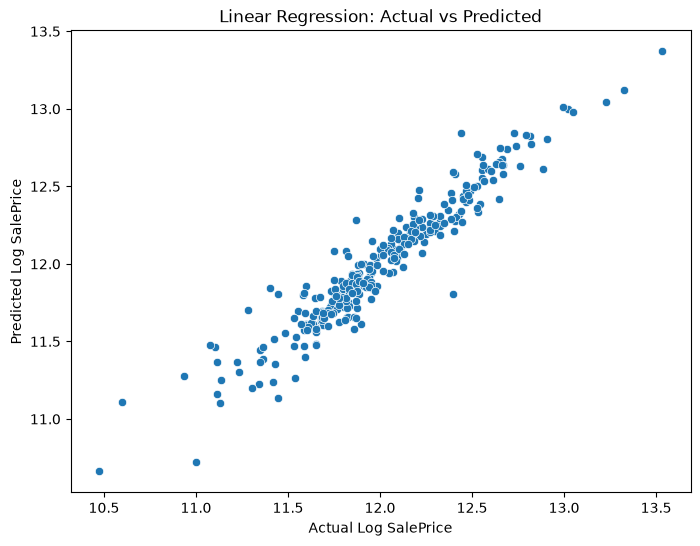

In [390]:
# Actual vs Predicted Plot
plt.figure(figsize=(8, 6))


sns.scatterplot(
    x=y_test,
    y=linear_predictions
)


plt.xlabel("Actual Log SalePrice")
plt.ylabel("Predicted Log SalePrice")


plt.title(
    "Linear Regression: Actual vs Predicted"
)


plt.show()

### Observations

- RMSE was used to evaluate the Linear Regression model.
- The model is evaluated on the unseen test data.
- A lower RMSE indicates better prediction performance.
- The actual vs predicted plot helps visualize how closely the predictions follow the actual values.
- This RMSE will be used as a baseline when comparing the other regression models.

## 19. Ridge Regression

In [391]:
# Import Ridge
from sklearn.linear_model import Ridge

In [392]:
# Create Ridge Regression Model
ridge_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            Ridge(alpha=10.0)
        )
    ]
)

In [393]:
# Train the Model
ridge_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](87,)","['MSSubClass','MSZoning','LotFrontage',...,'TotalPorchSF', 'TotalFinishedBsmtSF','OverallQual_GrLivArea']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,87
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be auto

In [394]:
# Make Predictions
ridge_predictions = ridge_model.predict(
    X_test
)

In [395]:
# Calculate RMSE
ridge_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ridge_predictions
    )
)


print(
    "Ridge Regression RMSE:",
    ridge_rmse
)

Ridge Regression RMSE: 0.13431029302323388


In [396]:
ridge_rmse = calculate_rmse(
    y_test,
    ridge_predictions
)

In [397]:
# Compare with Linear Regression
print("Linear Regression RMSE:", linear_rmse)
print("Ridge Regression RMSE:", ridge_rmse)

Linear Regression RMSE: 0.12970023501628017
Ridge Regression RMSE: 0.13431029302323388


### Observations

- Ridge Regression applies regularization to Linear Regression.
- The `alpha` parameter controls the strength of regularization.
- Ridge was evaluated using the same test set as Linear Regression.
- The RMSE can be compared with the Linear Regression baseline.

## 20. Lasso Regression

In [398]:
# Import Lasso
from sklearn.linear_model import Lasso

In [399]:
# Create Lasso Regression Model
lasso_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            Lasso(
                alpha=0.0005,
                max_iter=10000
            )
        )
    ]
)

In [400]:
# Train the Model
lasso_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](87,)","['MSSubClass','MSZoning','LotFrontage',...,'TotalPorchSF', 'TotalFinishedBsmtSF','OverallQual_GrLivArea']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,87
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be auto

In [401]:
# Make Predictions
lasso_predictions = lasso_model.predict(
    X_test
)

In [402]:
# Calculate RMSE
lasso_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        lasso_predictions
    )
)


print(
    "Lasso Regression RMSE:",
    lasso_rmse
)

Lasso Regression RMSE: 0.12731775959895414


In [403]:
lasso_rmse = calculate_rmse(
    y_test,
    lasso_predictions
)

In [404]:
# Compare Regression Models
print("Linear Regression RMSE:", linear_rmse)
print("Ridge Regression RMSE:", ridge_rmse)
print("Lasso Regression RMSE:", lasso_rmse)

Linear Regression RMSE: 0.12970023501628017
Ridge Regression RMSE: 0.13431029302323388
Lasso Regression RMSE: 0.12731775959895414


### Observations

- Lasso Regression applies L1 regularization.
- Lasso can shrink some feature coefficients to zero.
- The model was evaluated using RMSE on the unseen test data.
- Its performance can now be compared with Linear Regression and Ridge Regression.

## 21. Random Forest Regression

In [405]:
# Import Random Forest
from sklearn.ensemble import RandomForestRegressor

In [406]:
# Create Random Forest Model
random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [407]:
# Train the Model
random_forest_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](87,)","['MSSubClass','MSZoning','LotFrontage',...,'TotalPorchSF', 'TotalFinishedBsmtSF','OverallQual_GrLivArea']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,87
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be auto

In [408]:
# Make Predictions
random_forest_predictions = (
    random_forest_model.predict(
        X_test
    )
)

In [409]:
# Calculate RMSE
rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        random_forest_predictions
    )
)


print(
    "Random Forest RMSE:",
    rf_rmse
)

Random Forest RMSE: 0.14553383006741327


In [410]:
rf_rmse = calculate_rmse(
    y_test,
    random_forest_predictions
)

In [411]:
# Compare All Models
print("Linear Regression RMSE:", linear_rmse)
print("Ridge Regression RMSE:", ridge_rmse)
print("Lasso Regression RMSE:", lasso_rmse)
print("Random Forest RMSE:", rf_rmse)

Linear Regression RMSE: 0.12970023501628017
Ridge Regression RMSE: 0.13431029302323388
Lasso Regression RMSE: 0.12731775959895414
Random Forest RMSE: 0.14553383006741327


### Observations

- Random Forest is a tree-based ensemble regression model.
- It can capture non-linear relationships between features and house prices.
- The model was evaluated using the same test set as the previous models.
- RMSE provides a common metric for comparing all four models.

## 22. Model Comparison

In [412]:
# Create Model Comparison Table
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Random Forest"
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse,
        rf_rmse
    ]
})


results = results.sort_values(
    by="RMSE"
)
results.to_csv(
    "../Outputs/model_comparison.csv",
    index=False
)
display(results)

,Model,RMSE
2,Lasso Regression,0.127318
0,Linear Regression,0.129700
1,Ridge Regression,0.134310
3,Random Forest,0.145534


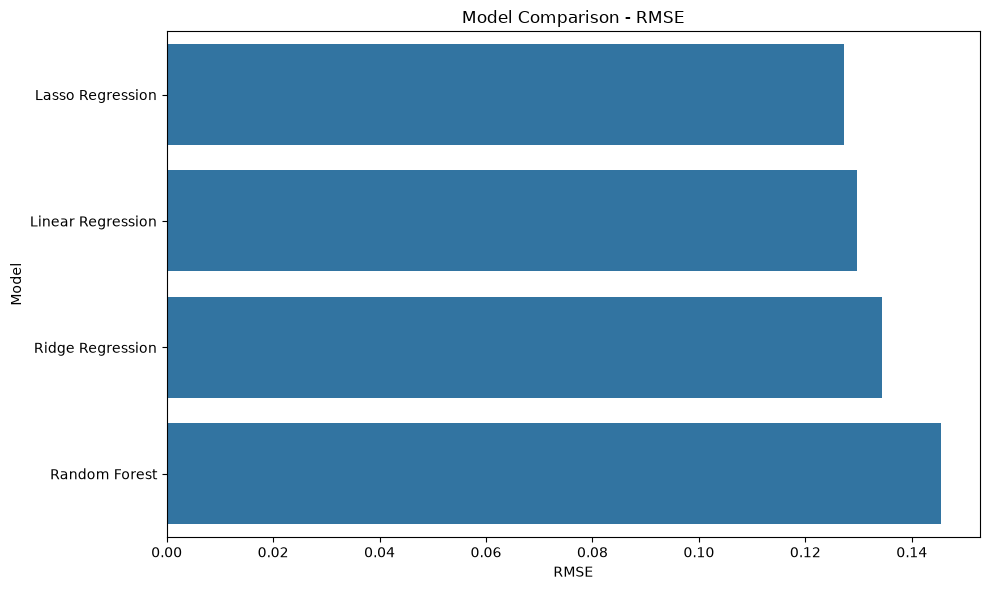

In [413]:
# Visualize RMSE
plt.figure(figsize=(10, 6))


sns.barplot(
    data=results,
    x="RMSE",
    y="Model"
)


plt.title("Model Comparison - RMSE")
plt.xlabel("RMSE")
plt.ylabel("Model")


plt.tight_layout()
plt.savefig("../Images/model_comparison_rmse.png")
plt.show()

In [414]:
# Identify Best Model
best_model = results.iloc[0]


print(
    "Best Model:",
    best_model["Model"]
)


print(
    "Best RMSE:",
    best_model["RMSE"]
)

Best Model: Lasso Regression
Best RMSE: 0.12731775959895414


### Observations

- All four regression models were compared using RMSE.
- RMSE provides a common metric for evaluating the models.
- A lower RMSE indicates better prediction performance.
- The model with the lowest RMSE on the test set is considered the best-performing model in this comparison.

## 23. Overfitting / Underfitting

In [415]:
# Calculate Training and Testing RMSE
linear_train_predictions = linear_model.predict(X_train)
ridge_train_predictions = ridge_model.predict(X_train)
lasso_train_predictions = lasso_model.predict(X_train)
rf_train_predictions = random_forest_model.predict(X_train)

model_fit_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Random Forest"
    ],
    "Training RMSE": [
        np.sqrt(mean_squared_error(y_train, linear_train_predictions)),
        np.sqrt(mean_squared_error(y_train, ridge_train_predictions)),
        np.sqrt(mean_squared_error(y_train, lasso_train_predictions)),
        np.sqrt(mean_squared_error(y_train, rf_train_predictions))
    ],
    "Testing RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse,
        rf_rmse
    ]
})

display(model_fit_results)

,Model,Training RMSE,Testing RMSE
0,Linear Regression,0.090053,0.129700
1,Ridge Regression,0.107092,0.134310
2,Lasso Regression,0.104279,0.127318
3,Random Forest,0.050738,0.145534


In [416]:
# Compare Training and Testing Performance
model_fit_results["RMSE Difference"] = (
    model_fit_results["Testing RMSE"]
    - model_fit_results["Training RMSE"]
)

display(model_fit_results)

,Model,Training RMSE,Testing RMSE,RMSE Difference
0,Linear Regression,0.090053,0.129700,0.039647
1,Ridge Regression,0.107092,0.134310,0.027218
2,Lasso Regression,0.104279,0.127318,0.023038
3,Random Forest,0.050738,0.145534,0.094796


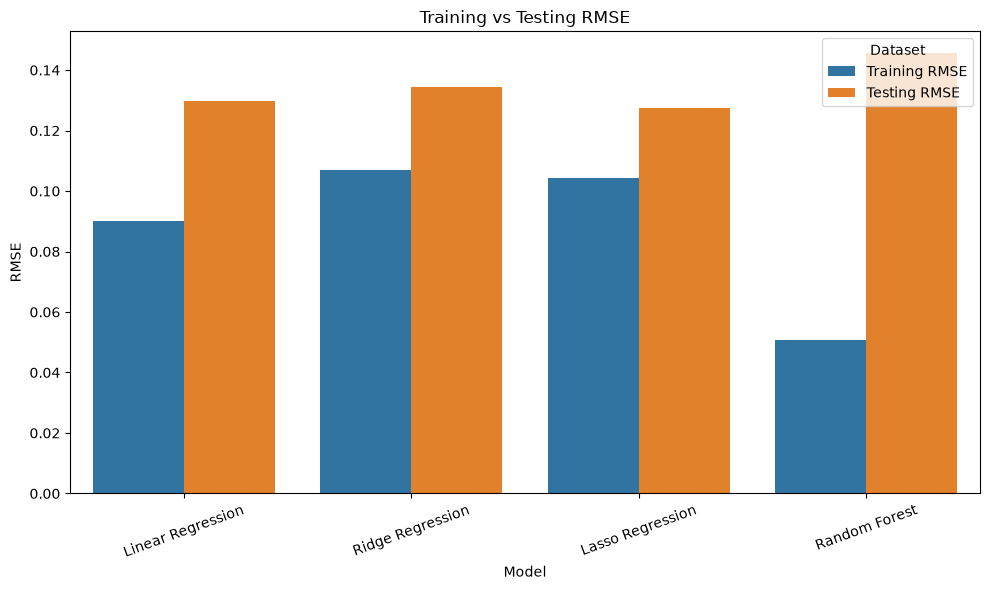

In [417]:
# Visualize Training vs Testing RMSE
plot_data = model_fit_results.melt(
    id_vars="Model",
    value_vars=[
        "Training RMSE",
        "Testing RMSE"
    ],
    var_name="Dataset",
    value_name="RMSE"
)


plt.figure(figsize=(10, 6))


sns.barplot(
    data=plot_data,
    x="Model",
    y="RMSE",
    hue="Dataset"
)


plt.title("Training vs Testing RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")


plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../Images/model_comparison_train_test_rmse.png")
plt.show()

### Observations

- Training and testing RMSE were compared to check model generalization.
- A large difference between training and testing RMSE can indicate overfitting.
- Similar training and testing performance generally indicates better generalization.
- Random Forest may show a larger training-testing gap because tree-based models can fit the training data closely.
- The test-set performance is more important for estimating how the model performs on unseen houses.

## 24. Feature Importance


In [418]:
# Extract Random Forest Components
rf_preprocessor = (
    random_forest_model
    .named_steps["preprocessor"]
)


rf_model = (
    random_forest_model
    .named_steps["model"]
)

In [419]:
# Get Processed Feature Names
feature_names = (
    rf_preprocessor
    .get_feature_names_out()
)

In [420]:
# Create Feature Importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})


feature_importance = (
    feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
)
feature_importance.to_csv(
    "../Outputs/feature_importance.csv",
    index=False
)

display(
    feature_importance.head(20)
)

,Feature,Importance
43,numerical__OverallQual_GrLivArea,0.605070
36,numerical__TotalSF,0.109100
3,numerical__OverallQual,0.029113
11,numerical__TotalBsmtSF,0.023910
25,numerical__GarageCars,0.016933
38,numerical__HouseAge,0.012617
253,categorical__GarageFinish_Unf,0.010743
5,numerical__YearBuilt,0.010630
37,numerical__TotalBathrooms,0.010433
8,numerical__BsmtFinSF1,0.009647


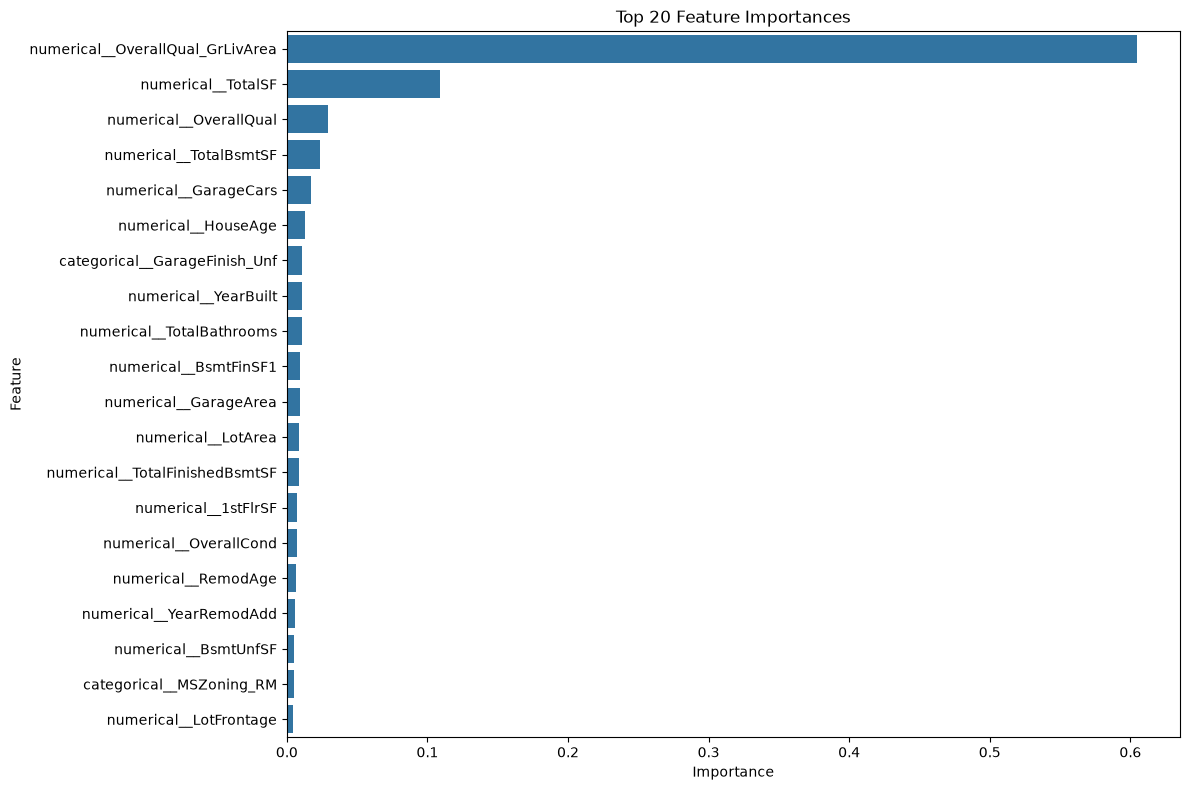

In [421]:
# Plot Top 20 Features
top_features = feature_importance.head(20)


plt.figure(figsize=(12, 8))


sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)


plt.title("Top 20 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")


plt.tight_layout()
plt.savefig("../Images/top_20_feature_importances.png")
plt.show()

In [422]:
# Save Feature Importance
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

### Observations

- `OverallQual_GrLivArea` was the most important feature in the Random Forest model, with an importance of approximately 0.605.
- `TotalSF` was the second most important feature, with an importance of approximately 0.109.
- `OverallQual` and `TotalBsmtSF` were also among the important predictors.
- Features related to house size, quality, basement, garage, and age appeared frequently among the top features.
- The engineered feature `OverallQual_GrLivArea` had substantially higher importance than the other features in this model.
- Feature importance represents how useful a feature was for the model's predictions and does not mean that the feature directly causes house prices to change.

## 25. Model Interpretation

In [423]:
# View Top Features
display(
    feature_importance.head(10)
)

,Feature,Importance
43,numerical__OverallQual_GrLivArea,0.605070
36,numerical__TotalSF,0.109100
3,numerical__OverallQual,0.029113
11,numerical__TotalBsmtSF,0.023910
25,numerical__GarageCars,0.016933
38,numerical__HouseAge,0.012617
253,categorical__GarageFinish_Unf,0.010743
5,numerical__YearBuilt,0.010630
37,numerical__TotalBathrooms,0.010433
8,numerical__BsmtFinSF1,0.009647


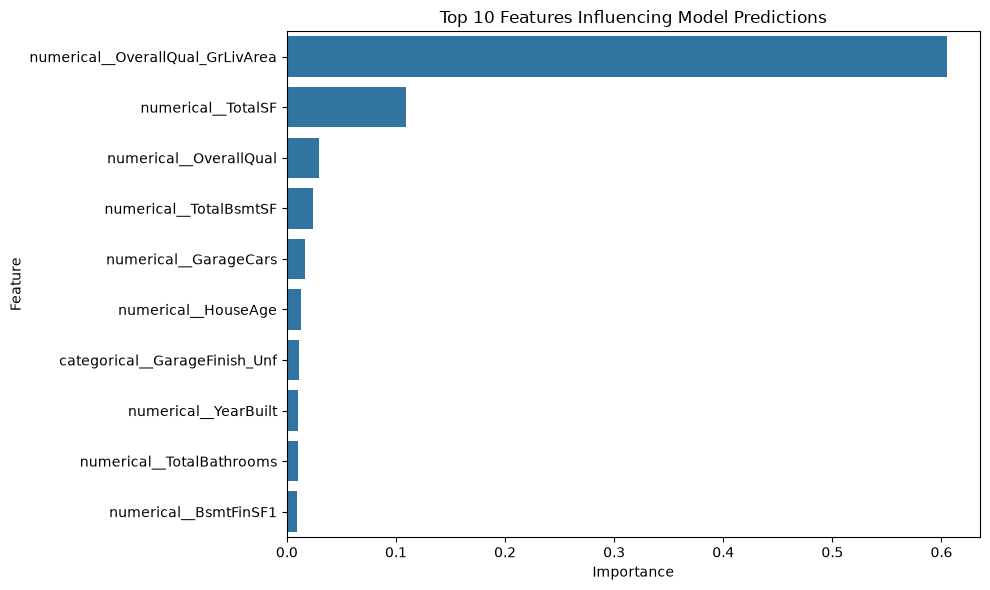

In [424]:
# Plot Top 10 Features
top_10_features = feature_importance.head(10)


plt.figure(figsize=(10, 6))


sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature"
)


plt.title("Top 10 Features Influencing Model Predictions")
plt.xlabel("Importance")
plt.ylabel("Feature")


plt.tight_layout()
plt.savefig("../Images/top_10_feature_importances.png")
plt.show()

In [425]:
# Separate Numerical and Categorical Important Features
top_numerical = feature_importance[
    feature_importance["Feature"].str.startswith(
        "numerical__"
    )
].head(10)


top_categorical = feature_importance[
    feature_importance["Feature"].str.startswith(
        "categorical__"
    )
].head(10)


print("Top Numerical Features:")
display(top_numerical)


print("Top Categorical Features:")
display(top_categorical)

Top Numerical Features:


,Feature,Importance
43,numerical__OverallQual_GrLivArea,0.605070
36,numerical__TotalSF,0.109100
3,numerical__OverallQual,0.029113
11,numerical__TotalBsmtSF,0.023910
25,numerical__GarageCars,0.016933
38,numerical__HouseAge,0.012617
5,numerical__YearBuilt,0.010630
37,numerical__TotalBathrooms,0.010433
8,numerical__BsmtFinSF1,0.009647
26,numerical__GarageArea,0.009480


Top Categorical Features:


,Feature,Importance
253,categorical__GarageFinish_Unf,0.010743
48,categorical__MSZoning_RM,0.004789
224,categorical__CentralAir_Y,0.004309
223,categorical__CentralAir_N,0.003597
232,categorical__KitchenQual_TA,0.003072
190,categorical__BsmtQual_Gd,0.002351
188,categorical__BsmtQual_Ex,0.002290
176,categorical__ExterQual_TA,0.001730
88,categorical__Neighborhood_OldTown,0.001208
264,categorical__PavedDrive_N,0.001042


In [426]:
# View Feature Importance as Percentages
top_features = feature_importance.head(10).copy()


top_features["Importance (%)"] = (
    top_features["Importance"] * 100
)


display(
    top_features[
        ["Feature", "Importance (%)"]
    ]
)

,Feature,Importance (%)
43,numerical__OverallQual_GrLivArea,60.506984
36,numerical__TotalSF,10.910040
3,numerical__OverallQual,2.911279
11,numerical__TotalBsmtSF,2.391042
25,numerical__GarageCars,1.693275
38,numerical__HouseAge,1.261747
253,categorical__GarageFinish_Unf,1.074316
5,numerical__YearBuilt,1.062972
37,numerical__TotalBathrooms,1.043316
8,numerical__BsmtFinSF1,0.964702


### Observations

- `OverallQual_GrLivArea` was the strongest predictor in the Random Forest model.
- `TotalSF` was the second most important feature.
- `OverallQual`, `TotalBsmtSF`, and `GarageCars` were also among the important predictors.
- The important features mainly represent house quality, size, basement, garage, and age-related characteristics.
- The engineered feature `OverallQual_GrLivArea` shows that combining existing features can provide useful predictive information.
- Feature importance describes the contribution of features to the model's predictions and should not be interpreted as causation.

## 26. Final Results

In [427]:
# Final Model Comparison
final_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Random Forest"
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse,
        rf_rmse
    ]
})


final_results = final_results.sort_values(
    by="RMSE"
)


display(final_results)

,Model,RMSE
2,Lasso Regression,0.127318
0,Linear Regression,0.129700
1,Ridge Regression,0.134310
3,Random Forest,0.145534


In [428]:
# Best Model
best_model_name = final_results.iloc[0]["Model"]
best_rmse = final_results.iloc[0]["RMSE"]


print("Best Model:", best_model_name)
print("Best RMSE:", best_rmse)

Best Model: Lasso Regression
Best RMSE: 0.12731775959895414


In [429]:
# Final Predictions
model_predictions = {
    "Linear Regression": linear_predictions,
    "Ridge Regression": ridge_predictions,
    "Lasso Regression": lasso_predictions,
    "Random Forest": random_forest_predictions
}


best_predictions = model_predictions[
    best_model_name
]

In [430]:
# Convert Predictions Back to Original Price
actual_prices = np.expm1(y_test)
predicted_prices = np.expm1(best_predictions)


prediction_df = pd.DataFrame({
    "Actual SalePrice": actual_prices,
    "Predicted SalePrice": predicted_prices
})
prediction_df.to_csv(
    "../Outputs/model_predictions.csv",
    index=False
)

display(
    prediction_df.head(10)
)

,Actual SalePrice,Predicted SalePrice
892,154500.0,153142.131837
1105,325000.0,331304.545814
413,115000.0,103515.550054
522,159000.0,159325.299295
1036,315500.0,328020.142663
614,75500.0,83314.977917
218,311500.0,250461.280987
1160,146000.0,139697.079830
649,84500.0,78399.148444
887,135500.0,143634.255423


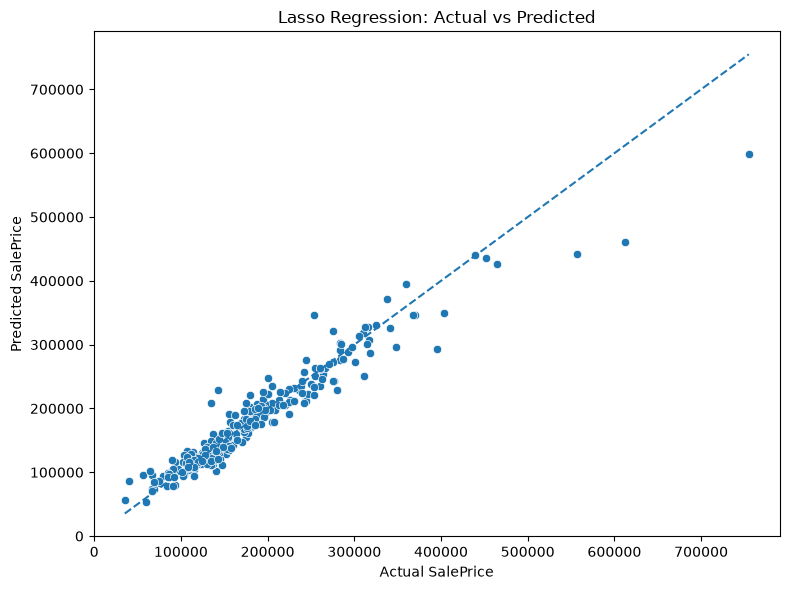

In [431]:
# Actual vs Predicted Prices
plt.figure(figsize=(8, 6))


sns.scatterplot(
    x=actual_prices,
    y=predicted_prices
)


minimum = min(
    actual_prices.min(),
    predicted_prices.min()
)


maximum = max(
    actual_prices.max(),
    predicted_prices.max()
)


plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)


plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")


plt.title(
    f"{best_model_name}: Actual vs Predicted"
)


plt.tight_layout()
plt.savefig("../Images/actual_vs_predicted_prices.png")
plt.show()

### Observations

- Lasso Regression achieved the lowest RMSE of **0.127318**.
- Linear Regression achieved the second-lowest RMSE of **0.129700**.
- Ridge Regression achieved an RMSE of **0.134310**.
- Random Forest achieved the highest RMSE of **0.145534** among the four models.
- Based on test-set RMSE, **Lasso Regression was selected as the best-performing model**.
- The results show that the regularized linear models performed better than Random Forest in this experiment.
- The RMSE values are calculated on the log-transformed `SalePrice`.

## 27. Business Insights

In [432]:
# Key Price Drivers
top_business_features = feature_importance.head(10)


display(
    top_business_features[
        ["Feature", "Importance"]
    ]
)

,Feature,Importance
43,numerical__OverallQual_GrLivArea,0.605070
36,numerical__TotalSF,0.109100
3,numerical__OverallQual,0.029113
11,numerical__TotalBsmtSF,0.023910
25,numerical__GarageCars,0.016933
38,numerical__HouseAge,0.012617
253,categorical__GarageFinish_Unf,0.010743
5,numerical__YearBuilt,0.010630
37,numerical__TotalBathrooms,0.010433
8,numerical__BsmtFinSF1,0.009647


### Business Insights

- Overall house quality and living space were among the strongest predictive factors for house prices.
- The engineered feature `OverallQual_GrLivArea` was the most important feature in the Random Forest model.
- Total house area (`TotalSF`) was also a strong predictor of SalePrice.
- Basement and garage-related features contributed useful predictive information.
- Property age-related features also appeared among the important predictors.
- These findings suggest that property quality, size, and major structural features are important considerations when estimating residential house prices.

## 28. Conclusion

This project used the Ames Housing dataset to predict residential house prices using regression techniques.

The workflow included data understanding, data quality investigation, exploratory data analysis, target transformation, feature engineering, preprocessing, and model comparison.

Four regression models were evaluated using RMSE on the log-transformed `SalePrice`. Lasso Regression achieved the best performance with an RMSE of **0.127318**.

Feature importance analysis showed that `OverallQual_GrLivArea` and `TotalSF` were among the strongest predictive features, highlighting the importance of house quality and overall size.

The actual vs. predicted plot shows that most predictions are reasonably close to the actual sale prices, although the model has larger errors for some higher-priced houses.

Overall, the project demonstrates that careful data analysis, feature engineering, and appropriate model selection are important for building an effective house price prediction model.